# Transfer Entropy — Sistemas de Monitoreo EPM y TPM
### Túnel de la Faja · Mina Antamina · Tesis de Maestría

---

**Objetivo de este cuaderno:**  
Calcular la Transfer Entropy entre las series del sistema TPM (fuente) y el sistema EPM (objetivo) para demostrar estadísticamente que existe un flujo de información dirigido en la dirección TPM → EPM.

**Referencia central:**  
Schreiber, T. (2000). *Measuring Information Transfer*. Physical Review Letters, **85**(2), 461–464.

---

## ¿Qué es la Transfer Entropy y por qué la necesitamos?

El problema central de la tesis requiere demostrar que las series del TPM contienen información sobre las series del EPM. La correlación de Pearson solo detecta dependencia **lineal**. La Transfer Entropy detecta cualquier forma de dependencia, incluyendo no lineal, **y además dice en qué dirección fluye la información**.

La fórmula es:

$$T_{TPM \to EPM}(\tau) = H\!\left(Y_{t+1} \mid Y_t\right) - H\!\left(Y_{t+1} \mid Y_t,\, X_{t-\tau}\right)$$

donde:
- $Y_t$ es el valor del EPM en el instante $t$ (sistema **objetivo**)
- $X_{t-\tau}$ es el valor del TPM en el instante $t - \tau$ (sistema **fuente**)
- $H(A \mid B)$ es la entropía condicional: cuánta incertidumbre queda sobre $A$ después de conocer $B$
- $\tau$ es el rezago temporal (en pasos de 30 minutos)

La diferencia mide exactamente: **¿en cuántos bits se reduce la incertidumbre sobre el futuro del EPM cuando además del pasado del EPM también conocemos el pasado del TPM?**

Si $T_{TPM \to EPM} > T_{EPM \to TPM}$, el TPM impulsa al EPM y no al revés.

In [1]:
pip install pyEDM

Could not fetch URL https://pypi.org/simple/pip/: There was a problem confirming the ssl certificate: HTTPSConnectionPool(host='pypi.org', port=443): Max retries exceeded with url: /simple/pip/ (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:997)'))) - skipping
Note: you may need to restart the kernel to use updated packages.


---
## Celda 1 · Importar librerías

In [2]:
import pyEDM
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# Configuración de figuras
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11
})

---
## Celda 2 · Cargar datos

**Nota (ya no aplica):** este bloque describía los datos sintéticos originales del prototipo (retardo de 3 pasos, 90 minutos, con una rejilla de 30 min). Desde la correccion de la celda de carga, se usan datos reales (`Data_limpia_completa/{EPM,TPM}_completo.csv`) resampleados a una rejilla de 6h sobre el tramo pre-brecha. La descripcion de acoplamiento sintetico de abajo ya no describe los datos que realmente se usan.


In [3]:
epm_raw = pd.read_csv("Data_limpia_completa/EPM_completo.csv", parse_dates=["date"])
tpm_raw = pd.read_csv("Data_limpia_completa/TPM_completo.csv", parse_dates=["date"])

BRECHA_INICIO = pd.Timestamp("2023-06-20")

# EPM y TPM tienen desfases de rejilla documentados (1h-17h segun el bloque):
# un join exacto por fecha solo encuentra 528 coincidencias de miles de filas.
# Se restringe al tramo pre-brecha (el tramo simultaneo que este notebook
# siempre uso) y se resamplea ambos a una rejilla comun de 6h para alinearlos
# sin forzar sincronizacion fila a fila.
epm_r = epm_raw[epm_raw['date'] < BRECHA_INICIO].set_index('date').sort_index().resample('6h').mean()
tpm_r = tpm_raw[tpm_raw['date'] < BRECHA_INICIO].set_index('date').sort_index().resample('6h').mean()

combinado = epm_r.join(tpm_r, how='inner', lsuffix='_epm')
combinado = combinado.ffill().bfill()  # resuelve los pocos NaN de borde que deja el resample

date_series = combinado.index.to_series().reset_index(drop=True)
epm = combinado[list(epm_r.columns)].reset_index(drop=True)
tpm = combinado[list(tpm_r.columns)].reset_index(drop=True)

#To numeric EPM
epm = epm.apply(pd.to_numeric, errors='coerce')
epm = epm.astype(float)

#to numeric TPM
tpm = tpm.apply(pd.to_numeric, errors='coerce')
tpm = tpm.astype(float)

#Corrijo algunos valores los cuales pierden el orden de magnitud (pierden el caracter decimal ,)
# (bug corregido: la version anterior indexaba tpm[mask] con una mascara que
# solo tenia las columnas POT, lo que ponia en NaN todas las columnas Tilt)
tpm_columns = [c for c in tpm.columns if "POT" in c]
tpm.loc[:, tpm_columns] = tpm[tpm_columns].where(tpm[tpm_columns] <= 1000, tpm[tpm_columns] / 1000)

epm = epm.ffill()
tpm = tpm.ffill()


In [4]:
epm

,Sensor 1 (5m),Sensor 2 (10m),Sensor 3 (5m),Sensor 4 (10m)
0,3158.6887,2792.5084,3170.7856,3004.6062
1,3158.6887,2792.9094,3171.8898,3004.6062
2,3158.6887,2792.5084,3173.7066,3004.6062
3,3159.5062,2792.5084,3172.3172,3004.6062
4,3159.1152,2792.2076,3171.8898,3004.6062
...,...,...,...,...
884,3162.3153,2787.1969,3175.0963,3005.2996
885,3161.8885,2790.5034,3173.7066,3005.2996
886,3161.8885,2790.2028,3173.7066,3005.2996
887,3162.7066,2786.7962,3175.0963,3004.9876


---
## Celda 3 · Visualizar las series

Antes de calcular cualquier cosa, siempre hay que ver los datos. Buscamos:
- Que ambas series muestren la tendencia de fluencia (crecimiento que se desacelera)
- Que las series del TPM y EPM tengan patrones visualmente similares — evidencia inicial de dependencia

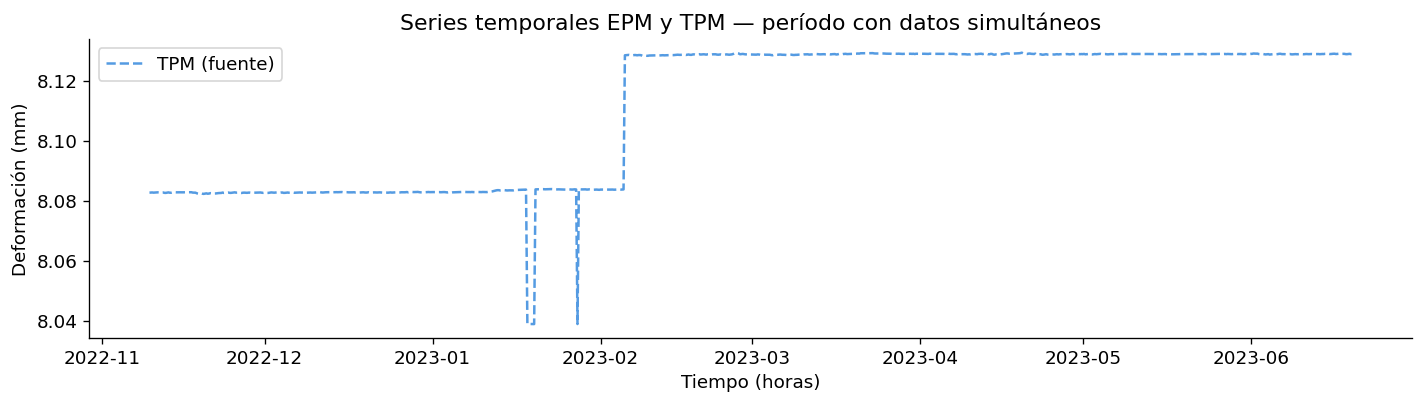

In [5]:
#t_horas = np.arange(N) * 30 / 60
t_horas = date_series

fig, ax = plt.subplots(figsize=(12, 3.5))

ax.plot(t_horas, tpm["POT(1)"], color='#378ADD', lw=1.5, ls='--', alpha=0.85, label='TPM (fuente)')
#ax.plot(t_horas, epm["Sensor 2 (10m)"], color='#1D9E75', lw=1.5,           alpha=0.85, label='EPM (objetivo)')

ax.set_xlabel('Tiempo (horas)')
ax.set_ylabel('Deformación (mm)')
ax.set_title('Series temporales EPM y TPM — período con datos simultáneos')
ax.legend()
plt.tight_layout()
plt.show()

---
## Celda 4 · La función de Transfer Entropy

### ¿Por qué necesitamos discretizar?

La fórmula de la Transfer Entropy requiere calcular probabilidades como $p(Y_{t+1}, Y_t, X_{t-\tau})$.

El problema es que tus datos son **valores continuos** (milímetros). La probabilidad de que el EPM mida exactamente $12.3871$ mm en un momento futuro es **cero** — nunca repetirás ese valor exacto. No puedes contar frecuencias de valores exactos.

La solución es **discretizar**: dividir el rango de valores en $B$ intervalos (bins) y reemplazar cada valor por el número de su intervalo. Así, en lugar de $12.3871$ mm, el valor se convierte en, por ejemplo, el bin número $3$ (deformación media-alta). Ahora sí puedes contar cuántas veces aparece el bin $3$.

Este es el **estimador de histograma** (Schreiber, 2000), el método estándar de la literatura.

In [6]:
def transfer_entropy(fuente, objetivo, tau, bins=5):
    """
    Calcula T(fuente → objetivo) al rezago tau.

    Fórmula (Schreiber, 2000):
        T = H(Y_futuro | Y_pasado) - H(Y_futuro | Y_pasado, X_pasado)

    Parámetros
    ----------
    fuente   : array 1D — serie del sistema fuente (TPM)
    objetivo : array 1D — serie del sistema objetivo (EPM)
    tau      : int — rezago en pasos temporales
    bins     : int — número de niveles de discretización (recomendado: 4–6)

    Retorna
    -------
    float — Transfer Entropy en bits (≥ 0)
    """

    # ── Paso 1: Discretizar ──────────────────────────────────────────────
    # Convertir valores continuos a enteros {0, 1, ..., bins-1}
    # Fórmula: bin_i = floor( (x_i - min) / (max - min) * bins )
    def discretizar(x):
        mn, mx = x.min(), x.max()
        idx = np.floor((x - mn) / (mx - mn + 1e-12) * bins).astype(int)
        return np.clip(idx, 0, bins - 1)

    X = discretizar(fuente)
    Y = discretizar(objetivo)
    n = len(Y)

    # ── Paso 2: Contar frecuencias conjuntas ─────────────────────────────
    # Para cada instante i, registramos la combinación:
    #   (Y en t+1,  Y en t,  X en t-tau)
    # y contamos cuántas veces aparece cada combinación.
    c_xyz = Counter()   # cuenta (Y_futuro, Y_pasado, X_pasado)
    c_yz  = Counter()   # cuenta (Y_futuro, Y_pasado)
    c_xz  = Counter()   # cuenta (Y_pasado, X_pasado)
    c_z   = Counter()   # cuenta (Y_pasado,)

    for i in range(tau, n - 1):
        y_futuro = Y[i + 1]
        y_pasado = Y[i]
        x_pasado = X[i - tau]

        c_xyz[(y_futuro, y_pasado, x_pasado)] += 1
        c_yz [(y_futuro, y_pasado)]           += 1
        c_xz [(y_pasado, x_pasado)]           += 1
        c_z  [(y_pasado,)]                    += 1

    total = sum(c_xyz.values())
    if total == 0:
        return 0.0

    # ── Paso 3: Calcular el log-ratio (la Transfer Entropy) ──────────────
    # La fórmula se reduce a sumar, para cada combinación observada:
    #   p(y_futuro, y_pasado, x_pasado) * log2[ p(y_futuro|y_pasado, x_pasado)
    #                                           / p(y_futuro|y_pasado) ]
    # que equivale a:
    #   (n_xyz / total) * log2[ (n_xyz * n_z) / (n_yz * n_xz) ]
    te = 0.0
    for (yf, yp, xp), n_xyz in c_xyz.items():
        n_yz = c_yz[(yf, yp)]
        n_xz = c_xz[(yp, xp)]
        n_z  = c_z [(yp,)]
        if n_yz > 0 and n_xz > 0 and n_z > 0:
            te += (n_xyz / total) * np.log2((n_xyz * n_z) / (n_yz * n_xz))

    return max(0.0, te)

print("Función transfer_entropy definida correctamente.")
print(f"Prueba rápida (τ=3): T(TPM→EPM) = {transfer_entropy(tpm['POT(7)'], epm['Sensor 1 (5m)'], tau=3):.4f} bits")

Función transfer_entropy definida correctamente.
Prueba rápida (τ=3): T(TPM→EPM) = 0.0674 bits


---
## Celda 5 · Calcular TE para varios rezagos

Calculamos la Transfer Entropy para rezagos de 1 a 19 pasos (6 horas a ~4.75 días, con pasos de 6h -- la rejilla real de los datos, no de 30 minutos) **en ambas direcciones**:

- $T_{TPM 	o EPM}(	au)$ — la direccion que nos interesa (¿el pasado del TPM ayuda a predecir el futuro del EPM?)
- $T_{EPM 	o TPM}(	au)$ — direccion control, para comparar


In [7]:
te_tpm_epm_dict = {}
te_epm_tpm_dict = {}

tpm_cols = list(filter(lambda x: not('freq' in x) , list(tpm.columns)))
epm_cols = list(filter(lambda x: "Sensor" in x,list(epm.columns)))
for tpm_col in tpm_cols:
  print("="*50,f"Serie: {tpm_col}")
  for epm_col in epm_cols:
    print(f"* Serie: {epm_col}")
    print(f"   Valores nulos: {epm[epm_col].isna().sum()}")
    lags         = np.arange(1, 20)                # rezagos: 1 a 12 pasos
    te_tpm_epm   = [transfer_entropy(tpm[tpm_col], epm[epm_col], tau=int(lag)) for lag in lags]
    te_epm_tpm   = [transfer_entropy(epm[epm_col], tpm[tpm_col], tau=int(lag)) for lag in lags]

    tau_optimo   = int(lags[np.argmax(te_tpm_epm)])
    tau_optimo_epm_tpm  = int(lags[np.argmax(te_epm_tpm)]) #Evaluando la dirección del flujo de información del EPM a TPM
    te_max       = max(te_tpm_epm)
    te_max_epm_tpm = max(te_epm_tpm)

    te_tpm_epm_dict.setdefault(tpm_col, {})
    te_epm_tpm_dict.setdefault(tpm_col, {})

    te_tpm_epm_dict[tpm_col].setdefault(epm_col, {
        "tau_optimo": tau_optimo,
        "te_max": te_max,
        "lags":lags,
        "te_tpm_epm": te_tpm_epm,
        "te_epm_tpm": te_epm_tpm,
        "te_max_epm_tpm": te_max_epm_tpm,
        "tau_optimo_epm_tpm": tau_optimo_epm_tpm
    })

    te_epm_tpm_dict[tpm_col].setdefault(epm_col, {
        "tau_optimo": tau_optimo_epm_tpm,
        "te_max": te_max_epm_tpm,
        "lags":lags,
        "te_epm_tpm": te_epm_tpm
    })

    print(f"   Rezago óptimo τ* = {tau_optimo} pasos  ({tau_optimo * 6} horas)")
    print(f"   T(TPM → EPM) máxima = {te_max:.4f} bits")
    print(f"   T(EPM → TPM) máxima = {max(te_epm_tpm):.4f} bits")
    print(f"   Razón de asimetría  = {te_max / max(te_epm_tpm):.2f}×")


================================================== Serie: POT(1)
* Serie: Sensor 1 (5m)
   Valores nulos: 0
   Rezago óptimo τ* = 1 pasos  (6 horas)
   T(TPM → EPM) máxima = 0.0639 bits
   T(EPM → TPM) máxima = 0.0129 bits
   Razón de asimetría  = 4.94×
* Serie: Sensor 2 (10m)
   Valores nulos: 0
   Rezago óptimo τ* = 16 pasos  (96 horas)
   T(TPM → EPM) máxima = 0.0719 bits
   T(EPM → TPM) máxima = 0.0114 bits
   Razón de asimetría  = 6.28×
* Serie: Sensor 3 (5m)
   Valores nulos: 0
   Rezago óptimo τ* = 8 pasos  (48 horas)
   T(TPM → EPM) máxima = 0.0900 bits
   T(EPM → TPM) máxima = 0.0101 bits
   Razón de asimetría  = 8.92×
* Serie: Sensor 4 (10m)
   Valores nulos: 0
   Rezago óptimo τ* = 1 pasos  (6 horas)
   T(TPM → EPM) máxima = 0.0322 bits
   T(EPM → TPM) máxima = 0.0023 bits
   Razón de asimetría  = 14.23×
================================================== Serie: POT(2)
* Serie: Sensor 1 (5m)
   Valores nulos: 0
   Rezago óptimo τ* = 7 pasos  (42 horas)
   T(TPM → EPM) máxima 

---
## Celda 6 · Visualizar TE vs rezago

La figura más importante del análisis. Lo que buscamos:

1. La **curva azul** (TPM→EPM) tiene un pico en $	au^*$ — este es el rezago donde la dependencia estadística dirigida es mayor, **no** se interpreta como un retardo físico de propagación en el macizo (ver Celda de discusión de $	au^*$ en el cuaderno de revisión rigurosa: entre 56 pares, $	au^*$ no muestra un patrón consistente).
2. La curva azul por **encima** de la curva naranja (EPM→TPM) es evidencia de **asimetría direccional** (dependencia estadística dirigida), no de causalidad física.
3. Lo esperable es que la curva TPM→EPM esté por encima del umbral rojo (significancia estadística) y la curva de control EPM→TPM **no necesariamente** — si ambas están igual de por encima del umbral, eso no distingue direccion.


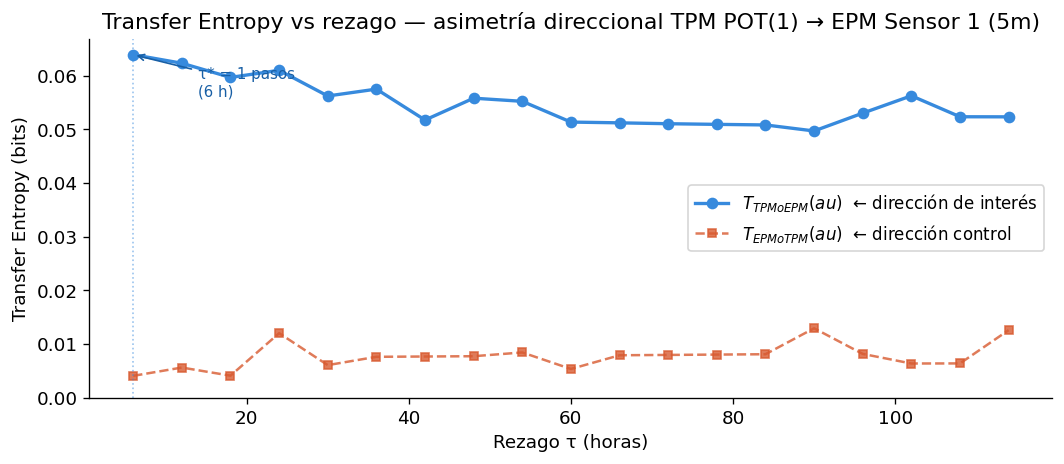

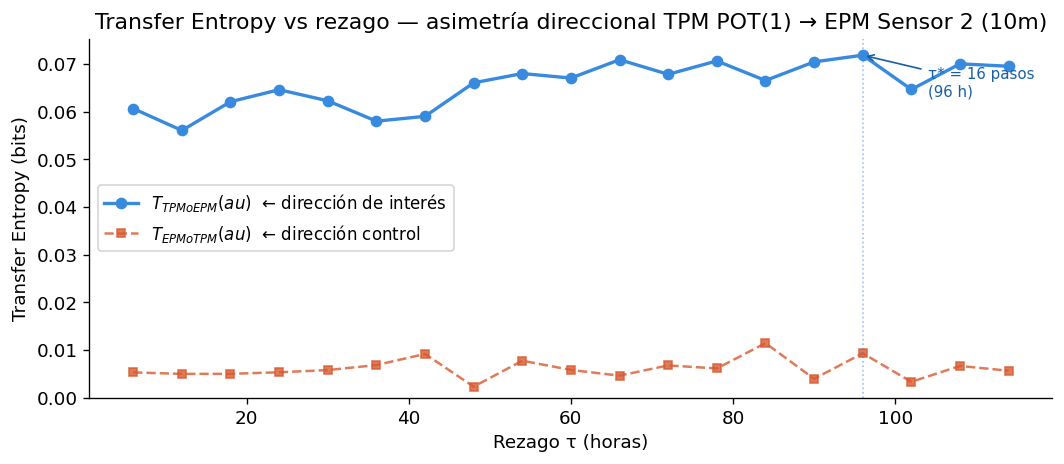

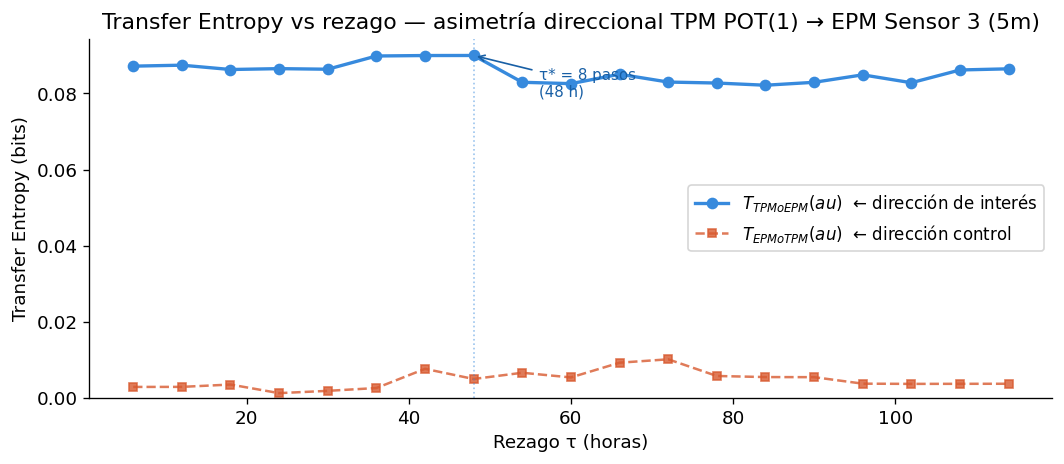

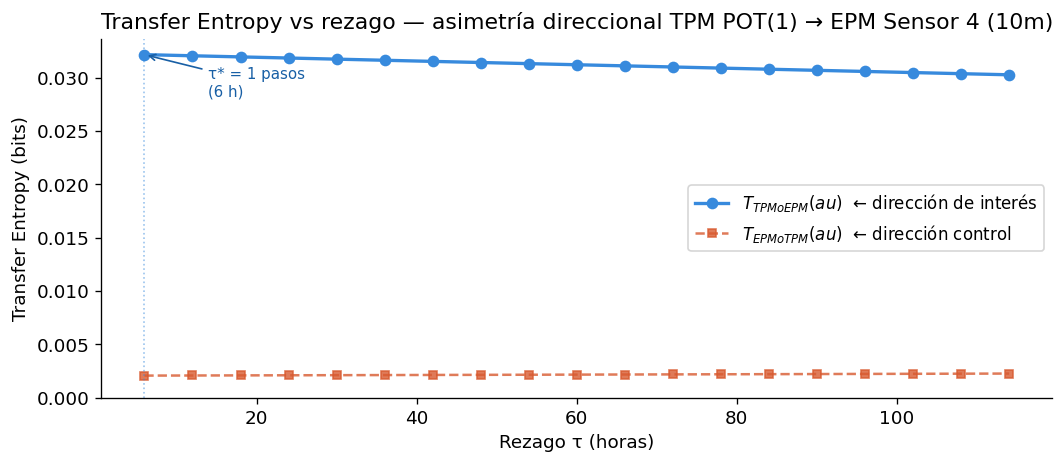

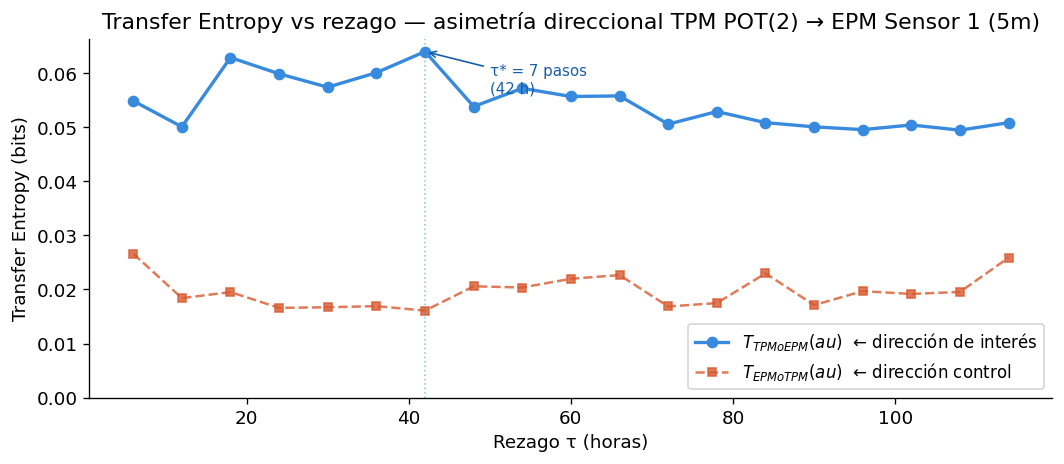

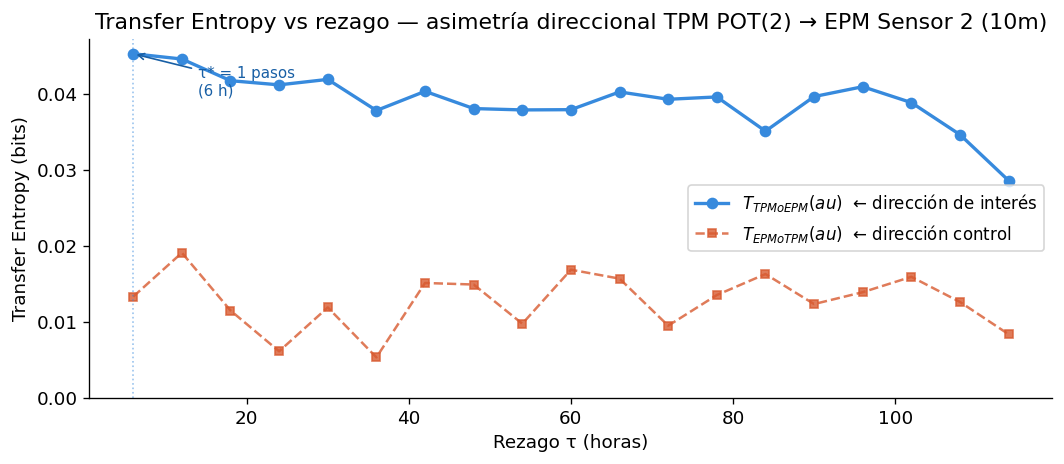

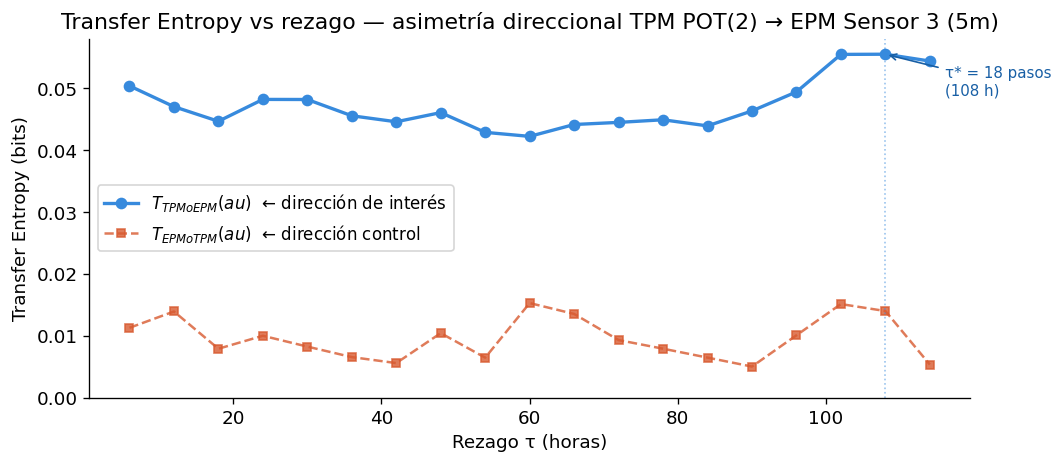

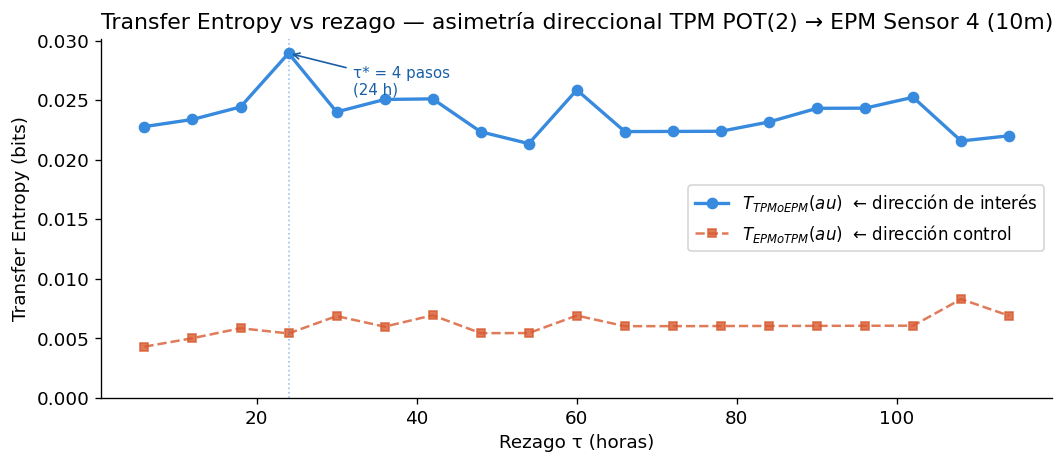

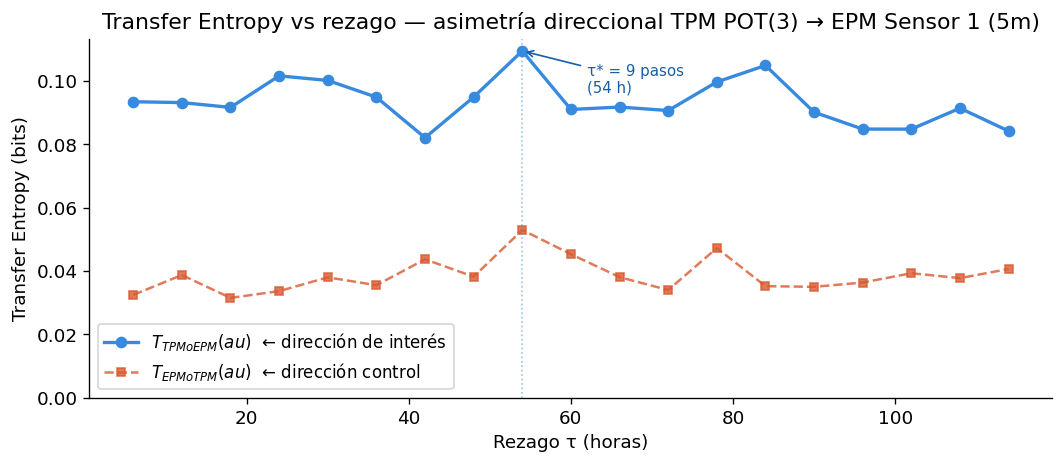

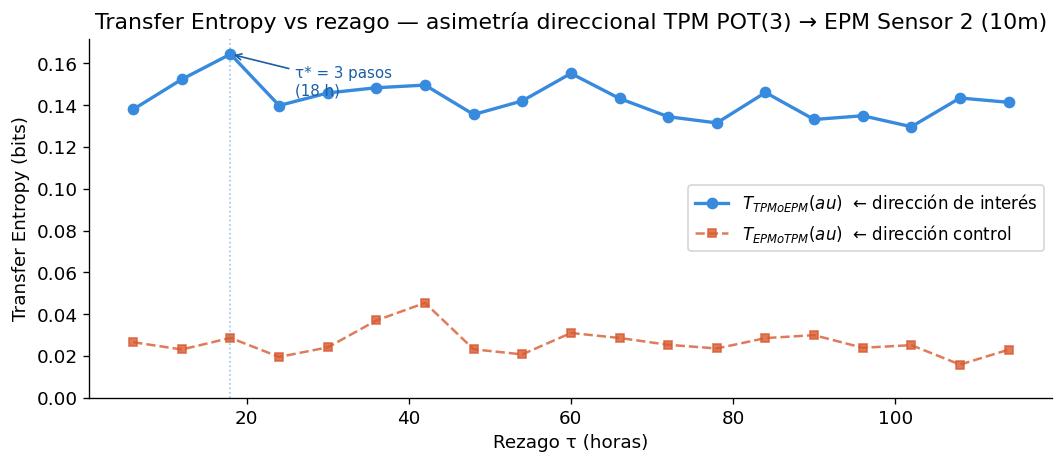

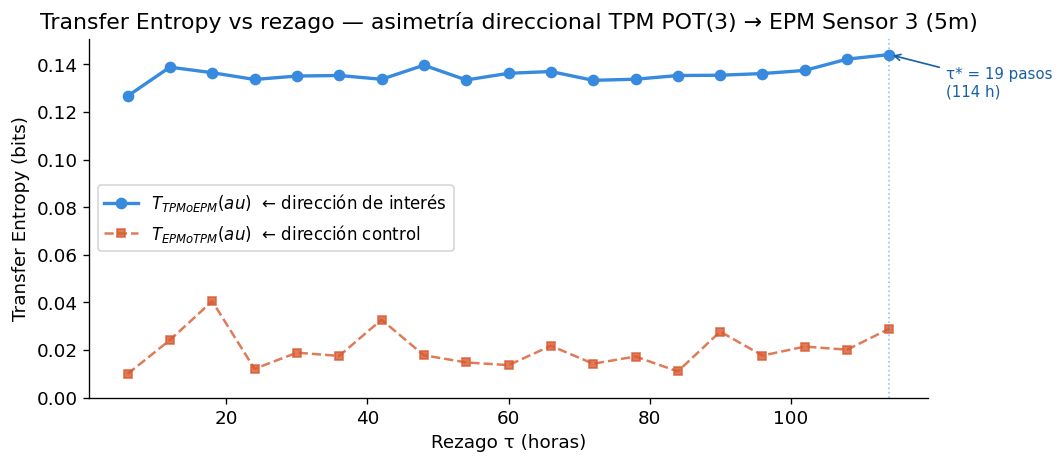

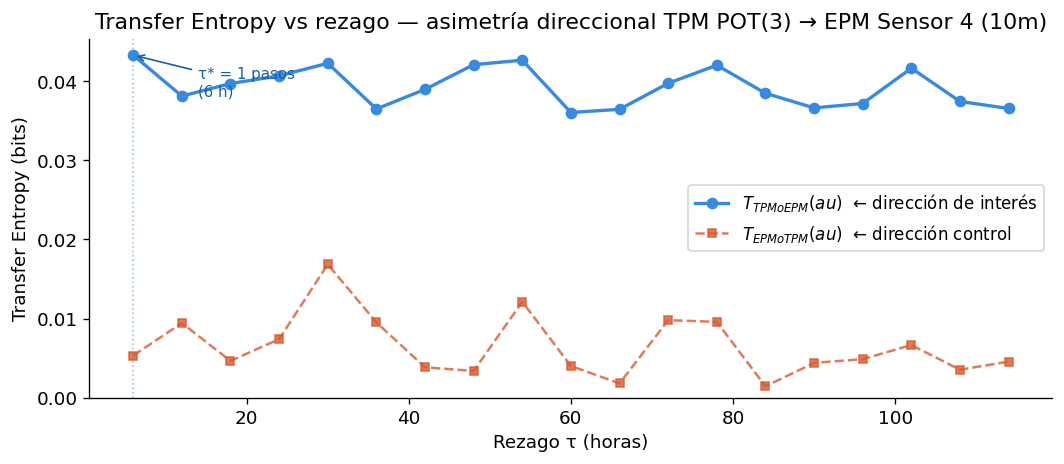

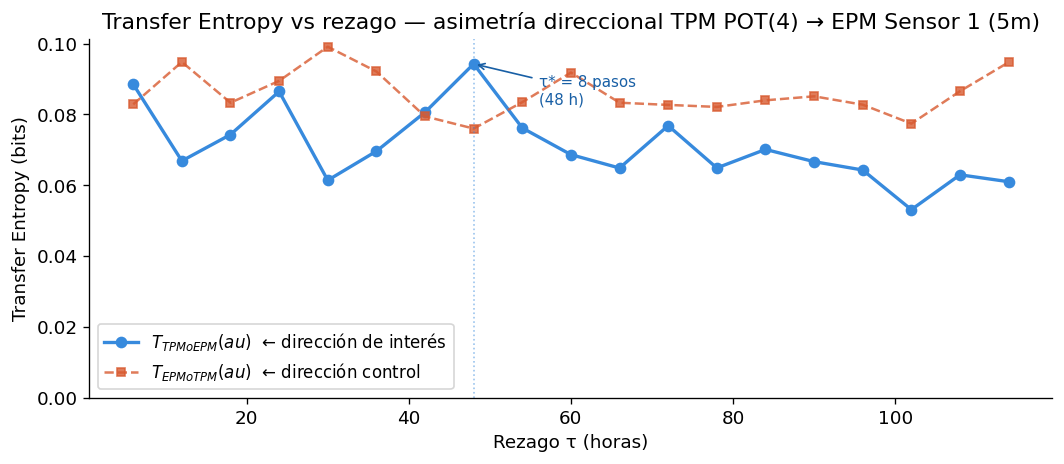

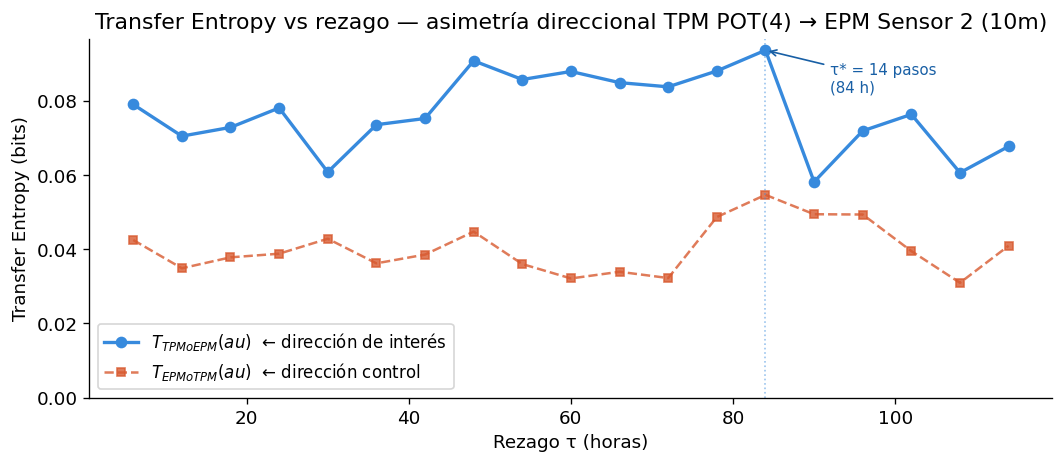

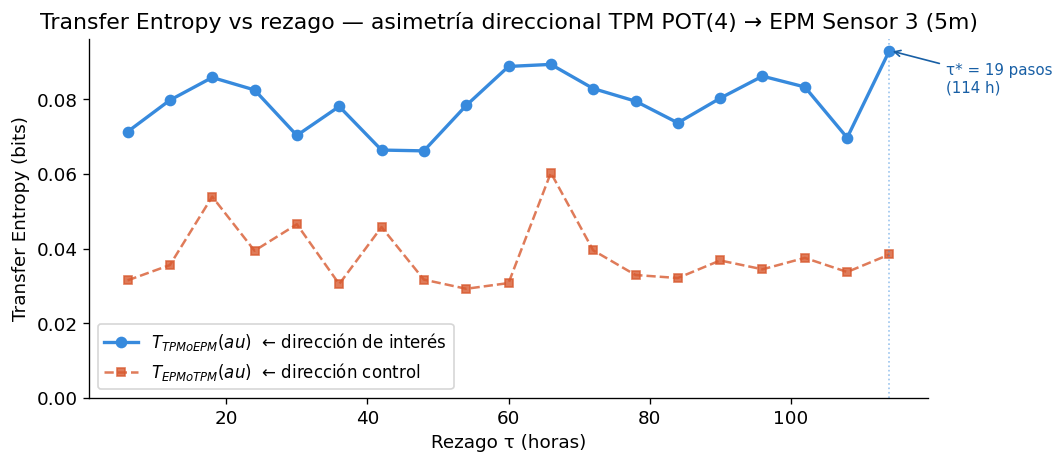

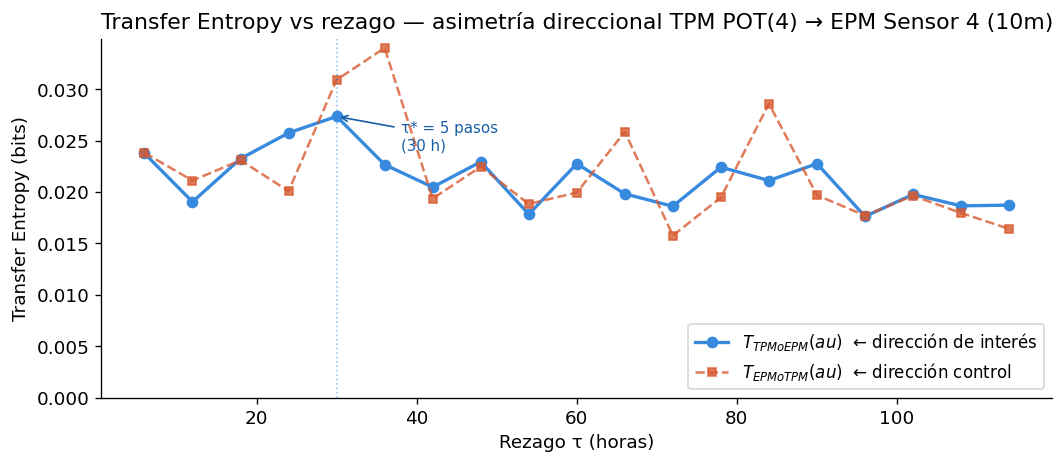

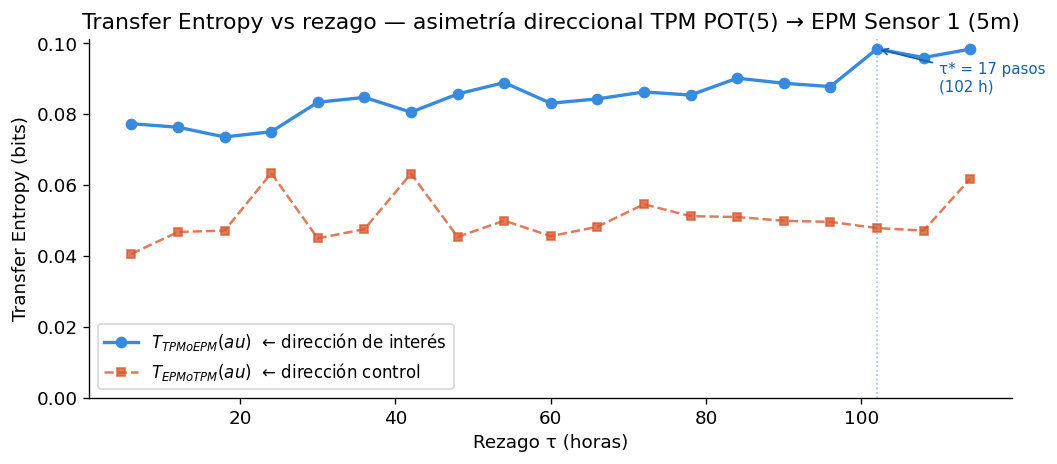

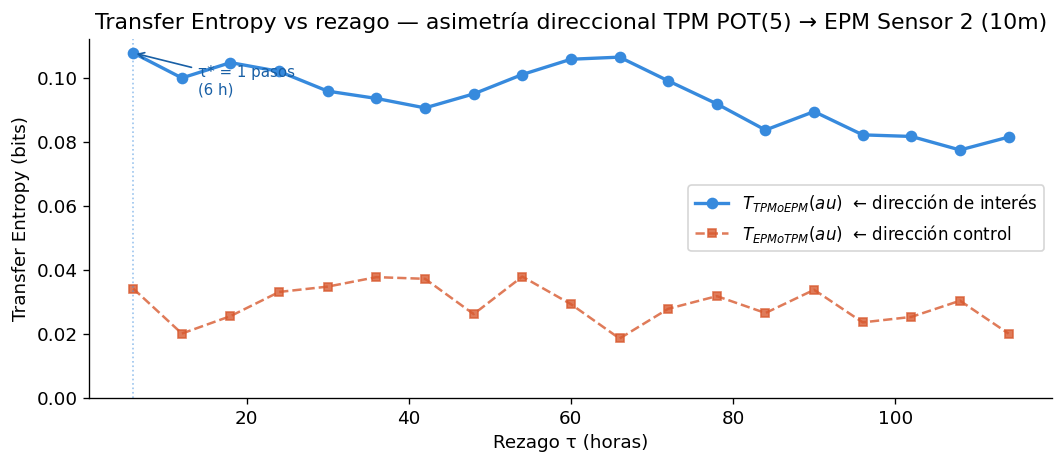

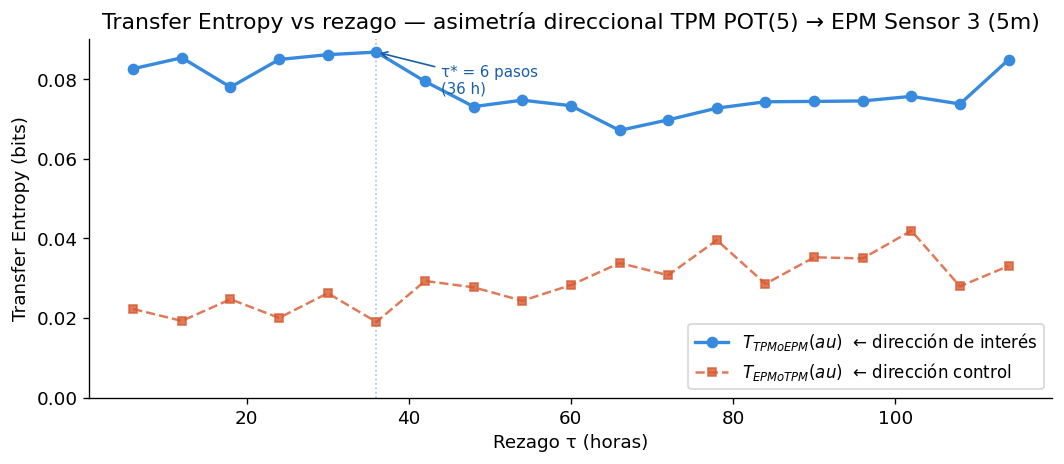

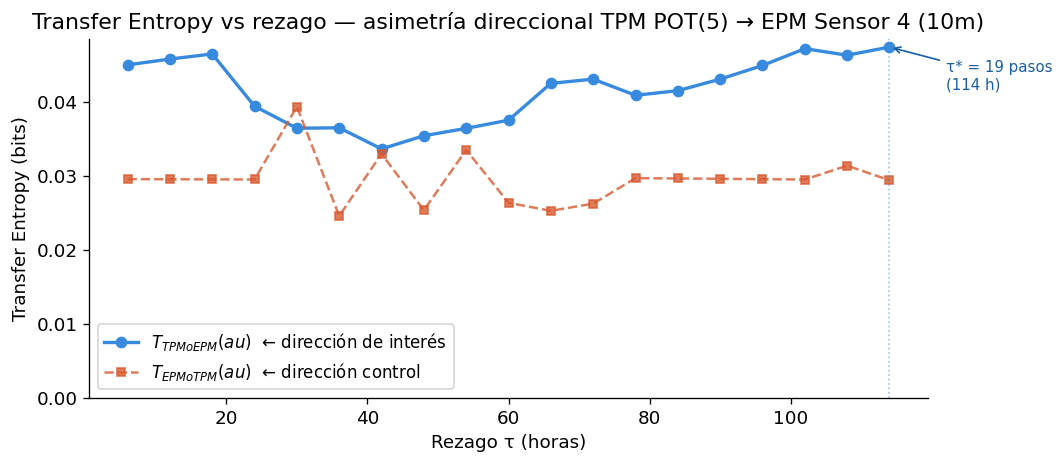

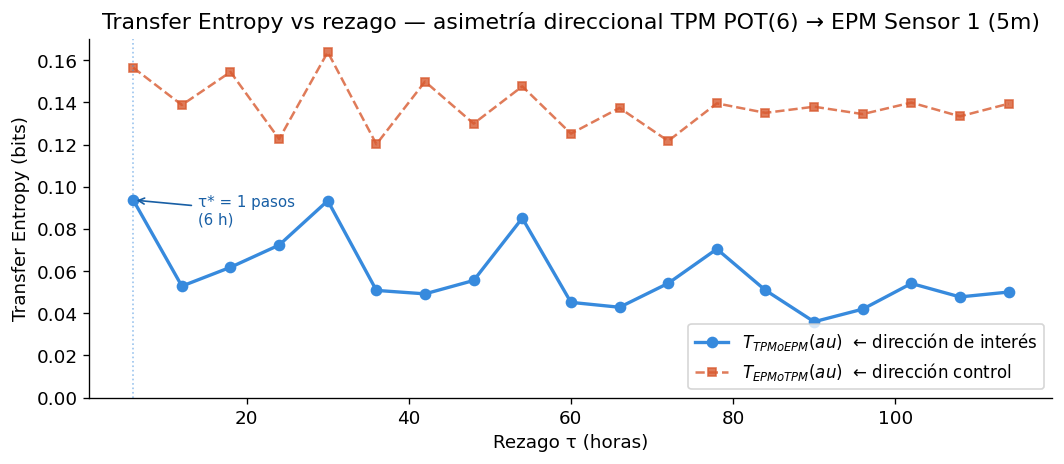

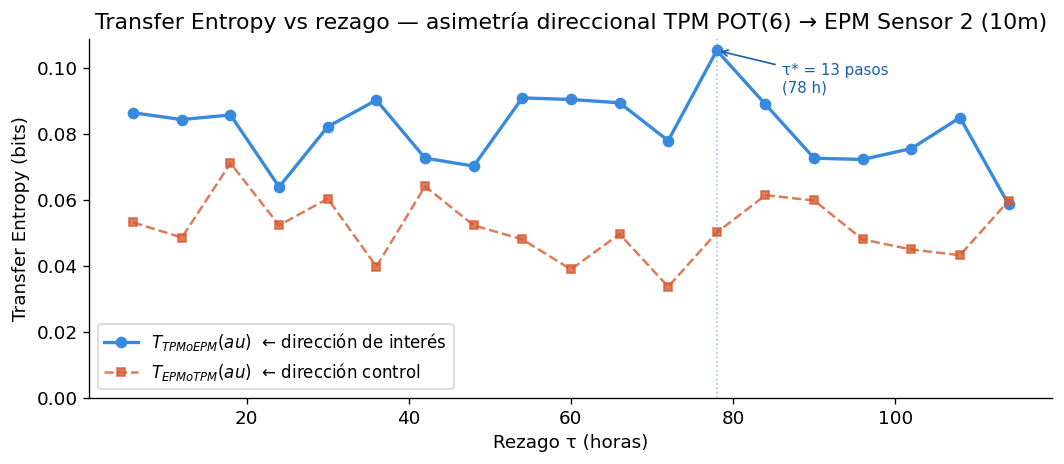

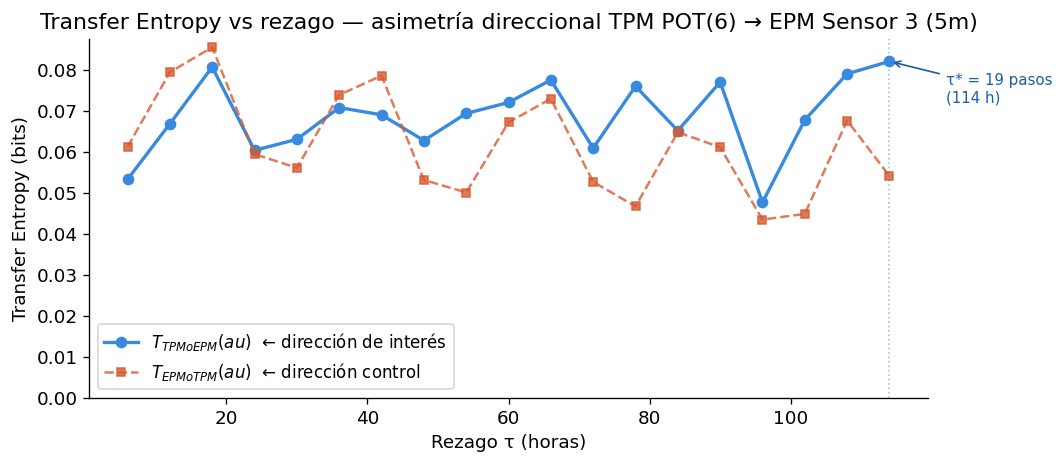

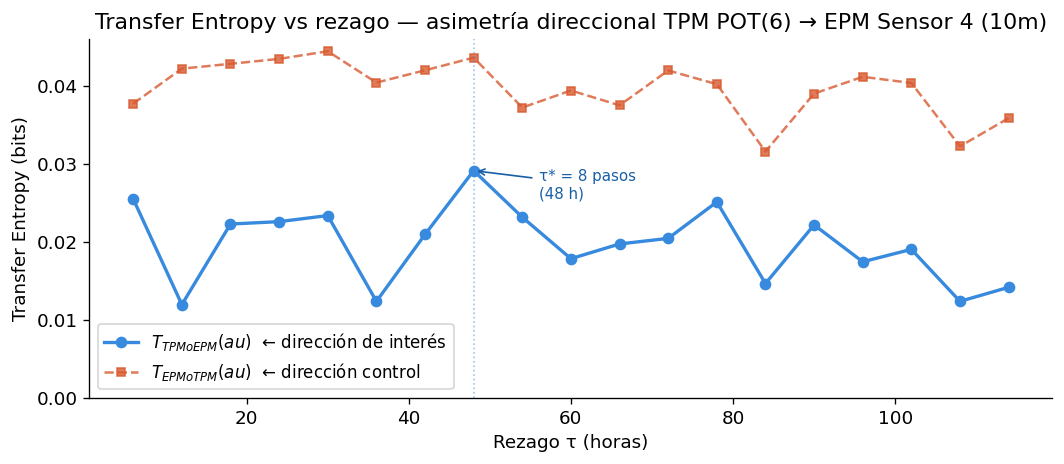

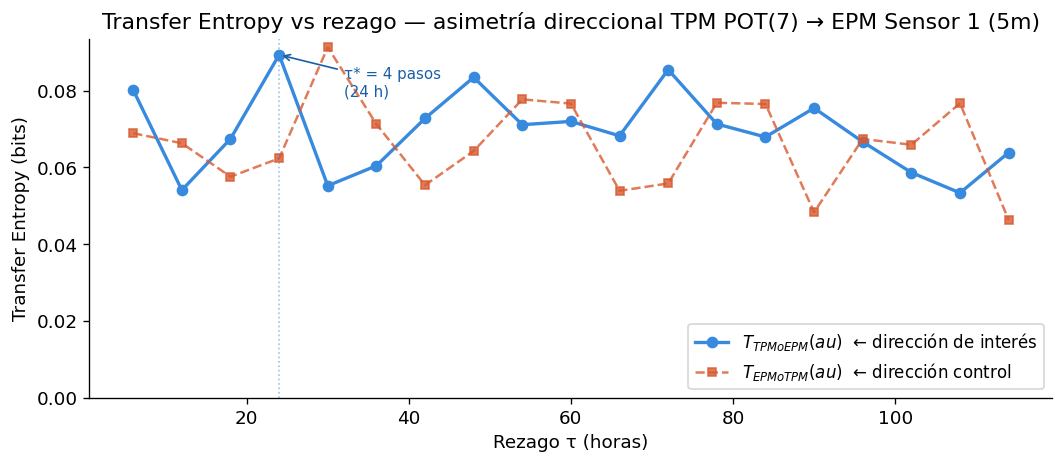

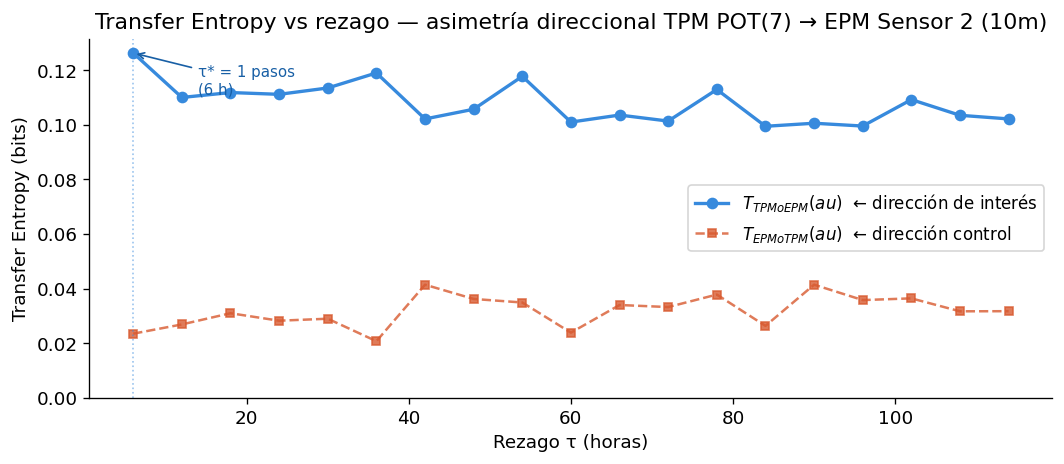

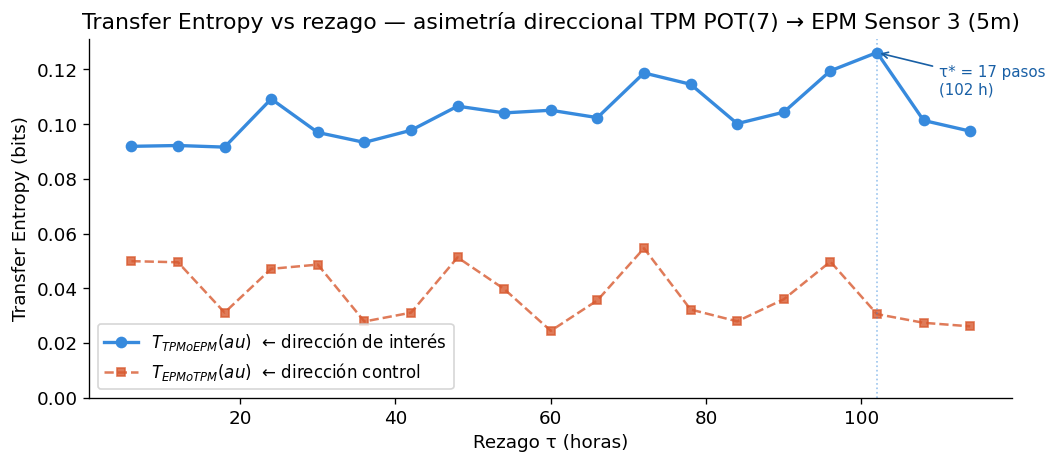

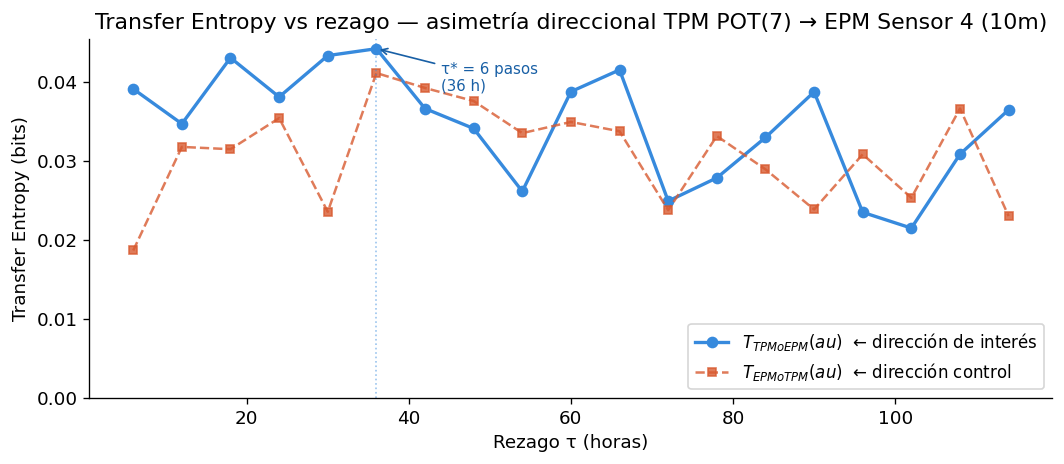

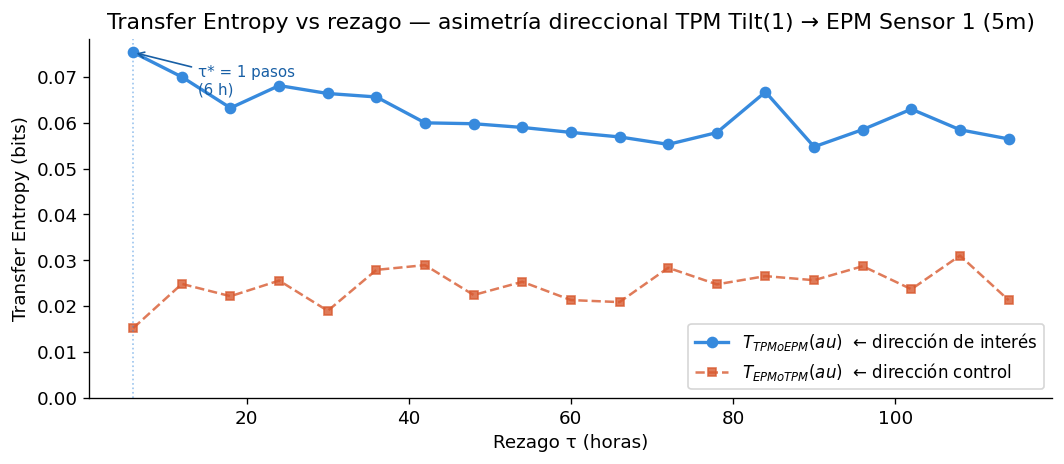

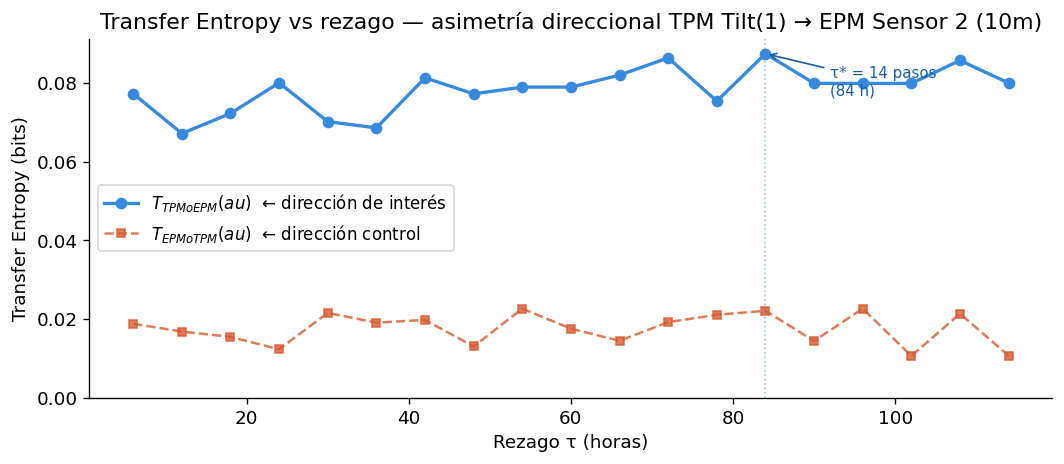

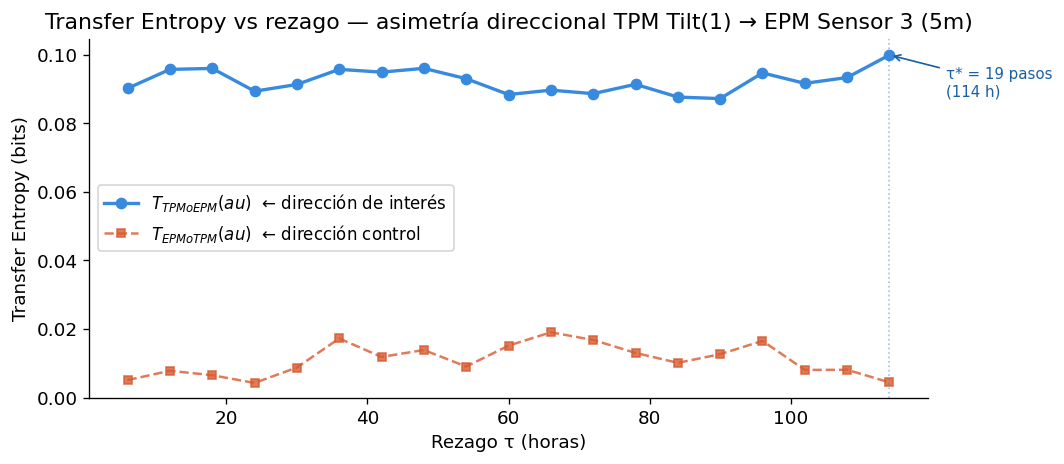

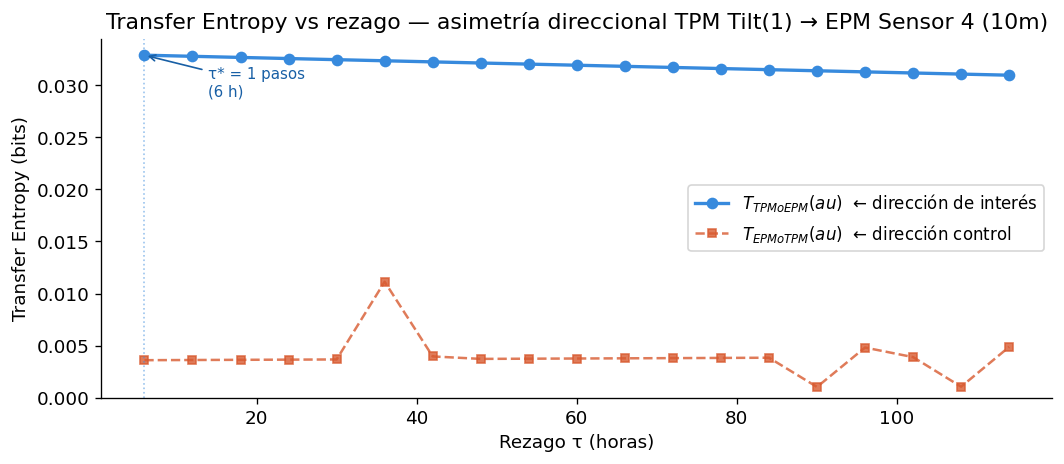

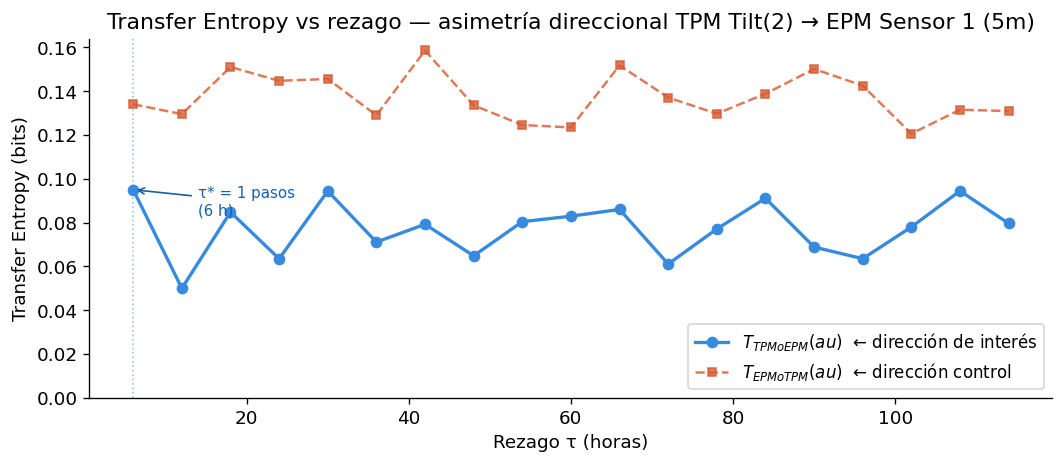

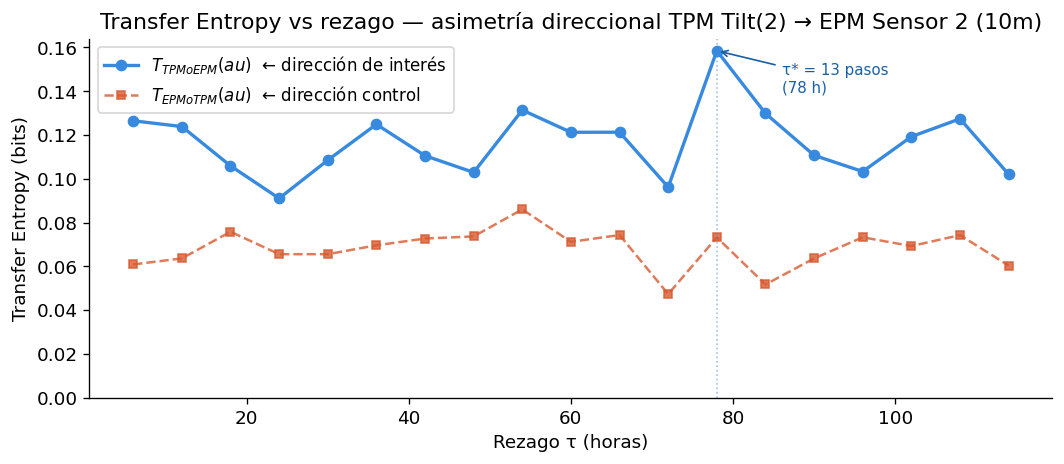

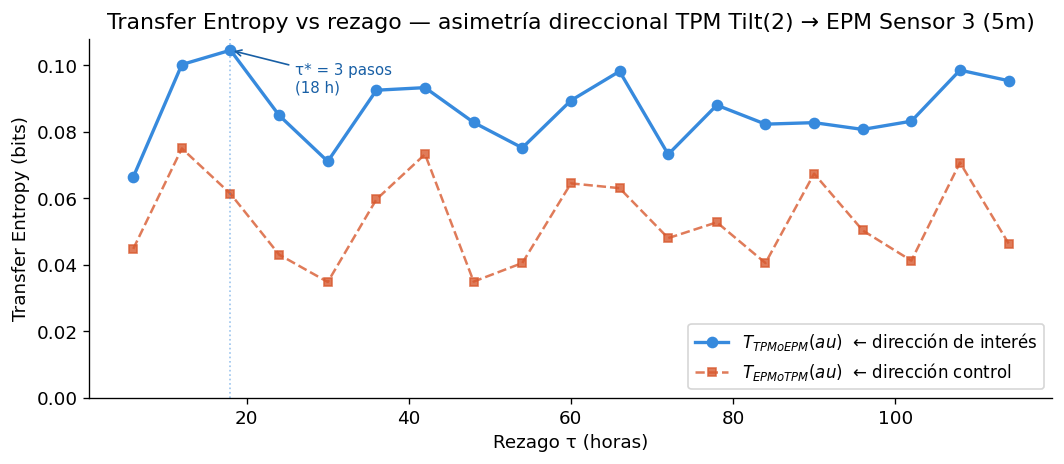

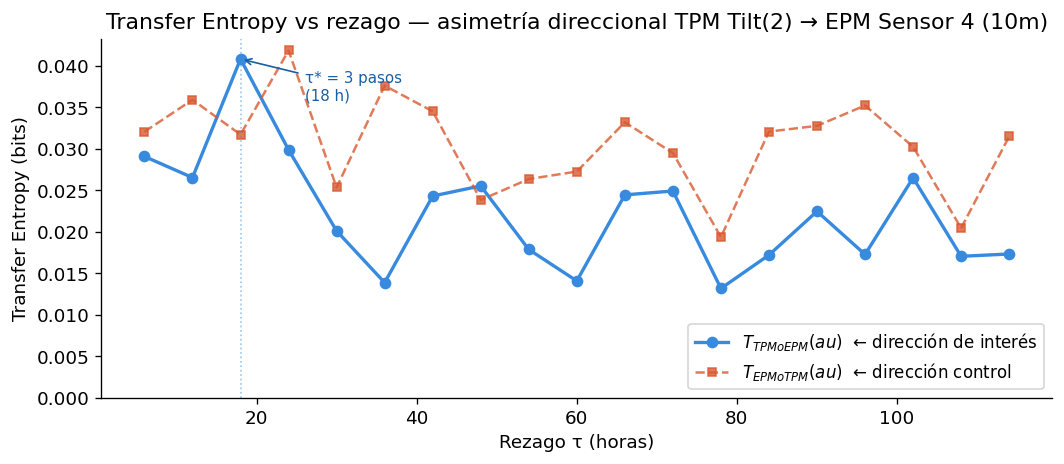

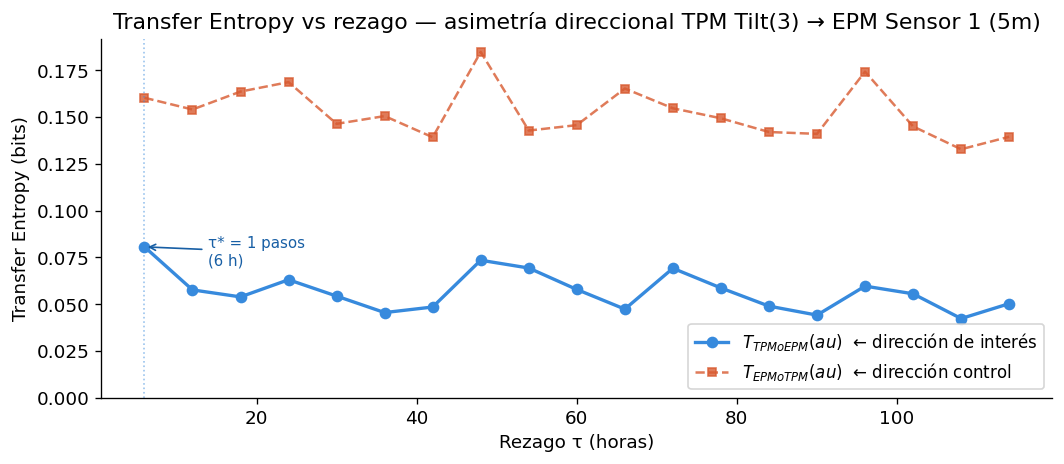

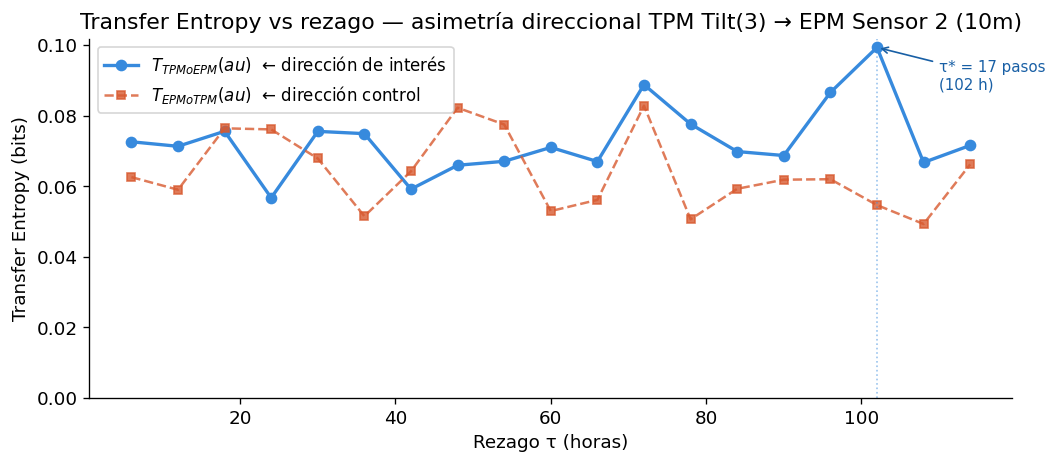

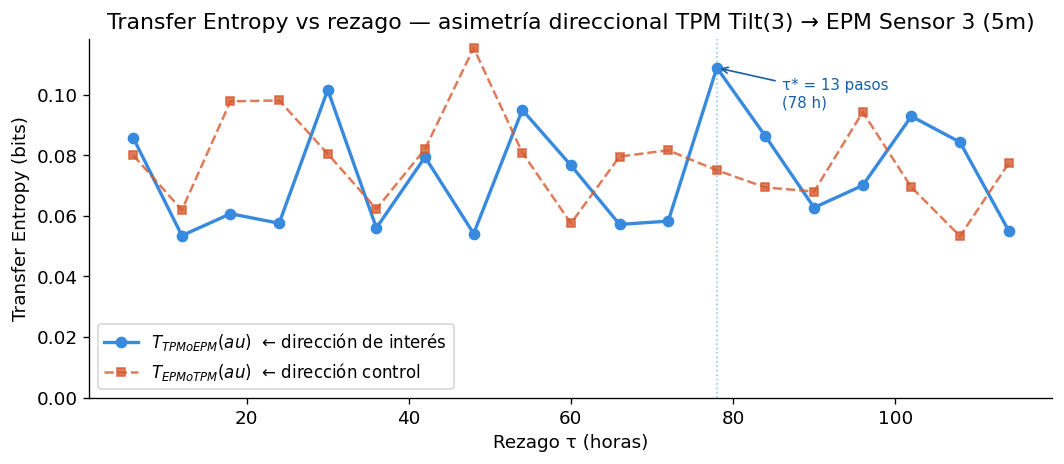

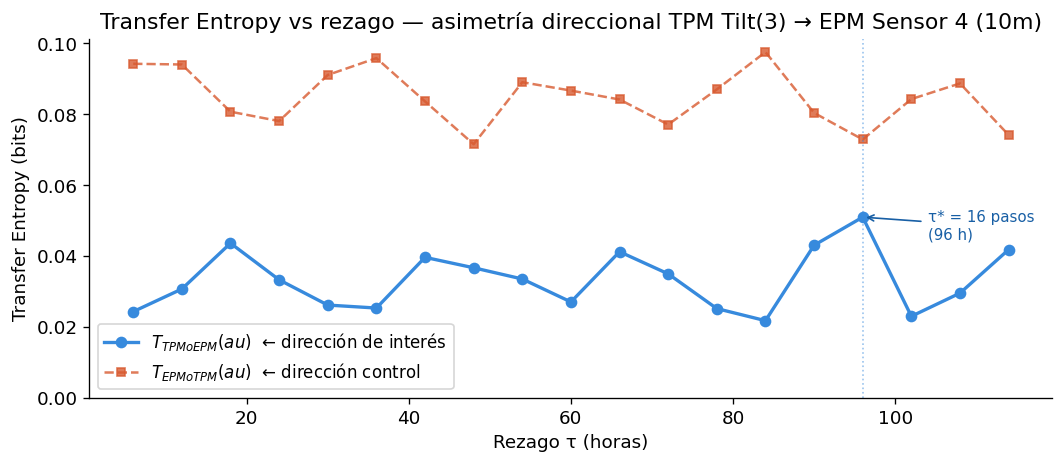

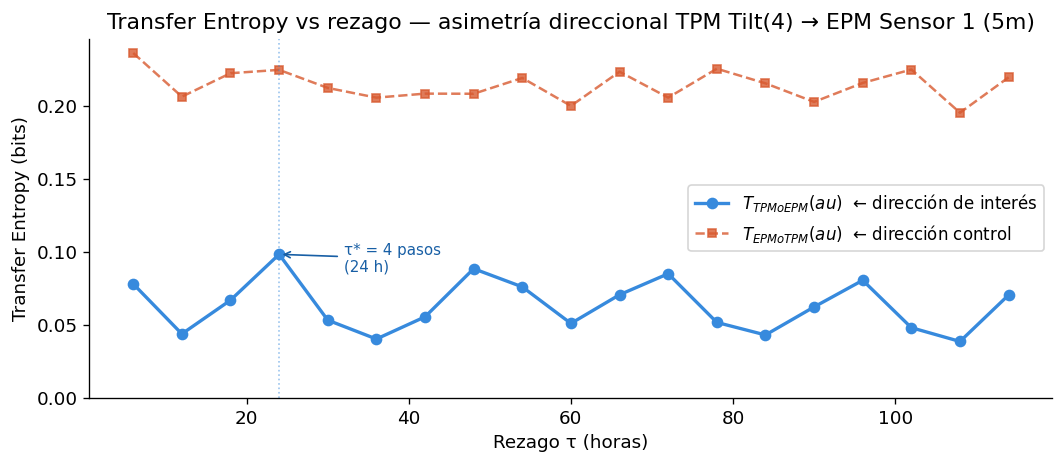

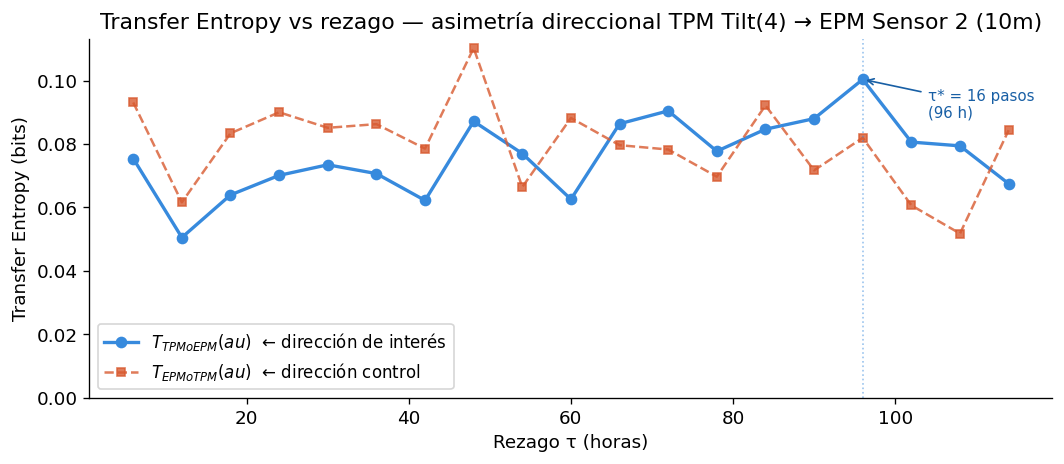

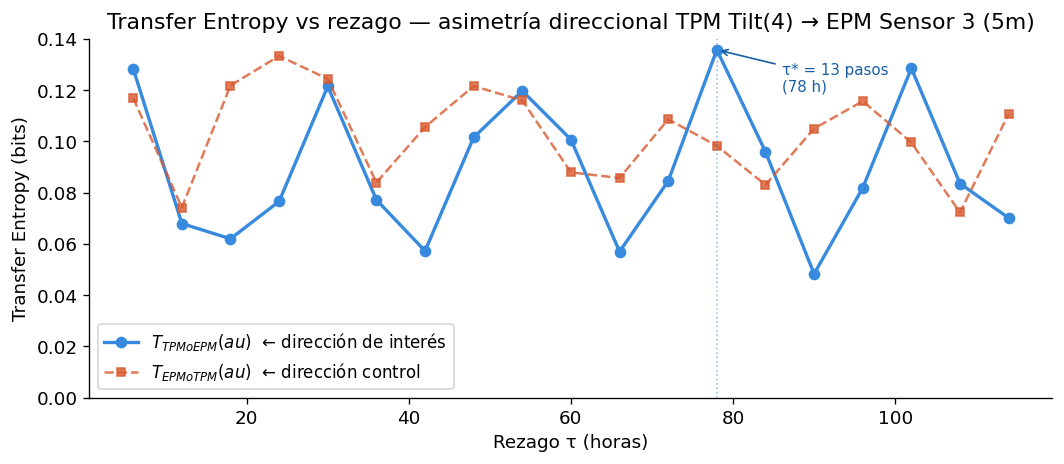

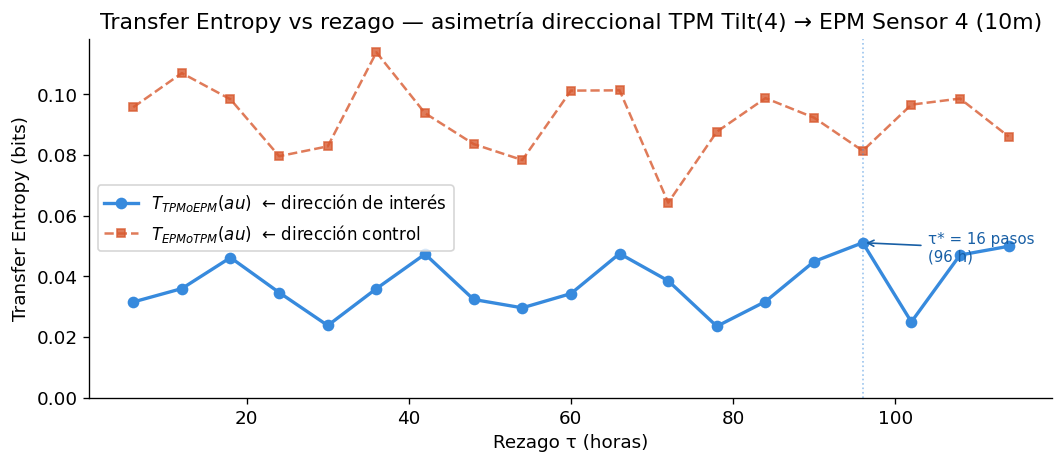

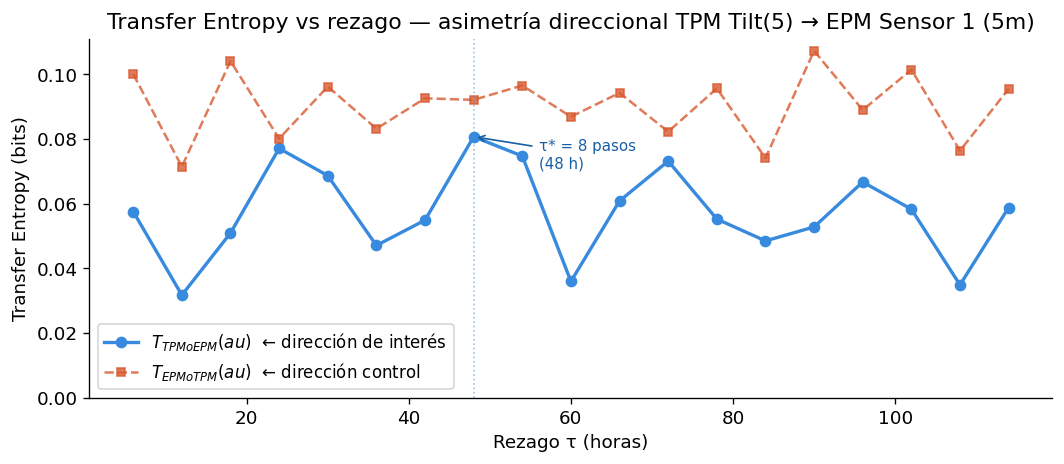

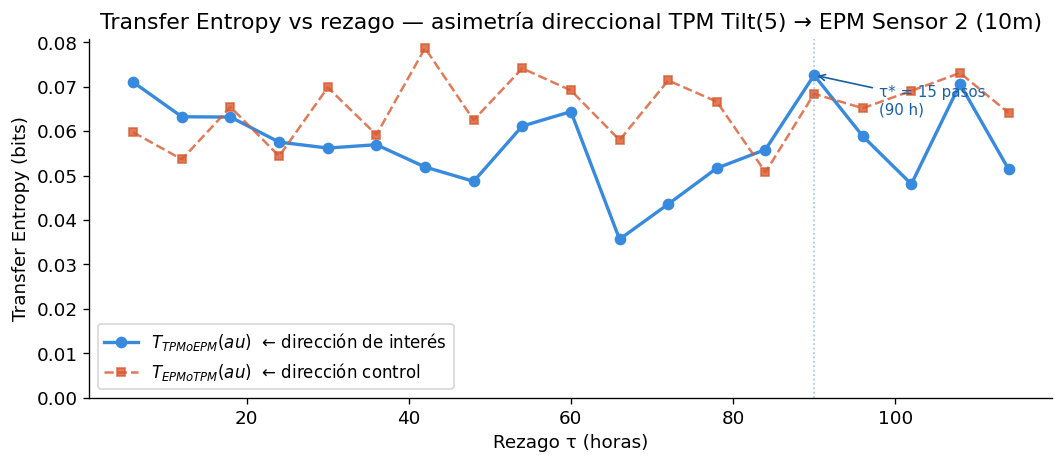

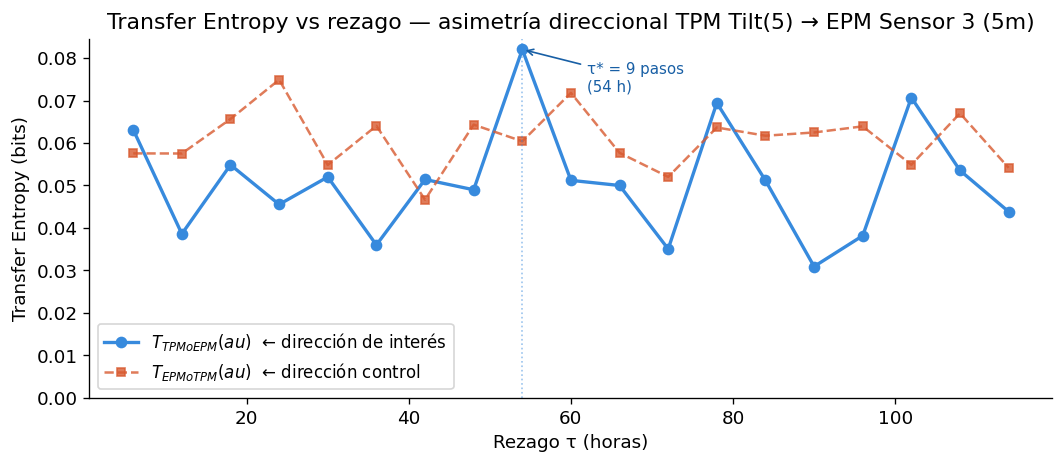

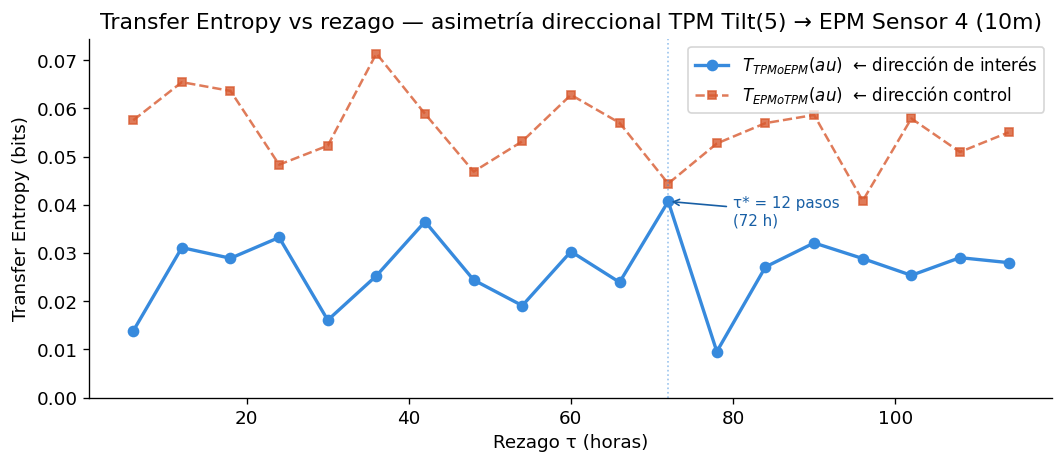

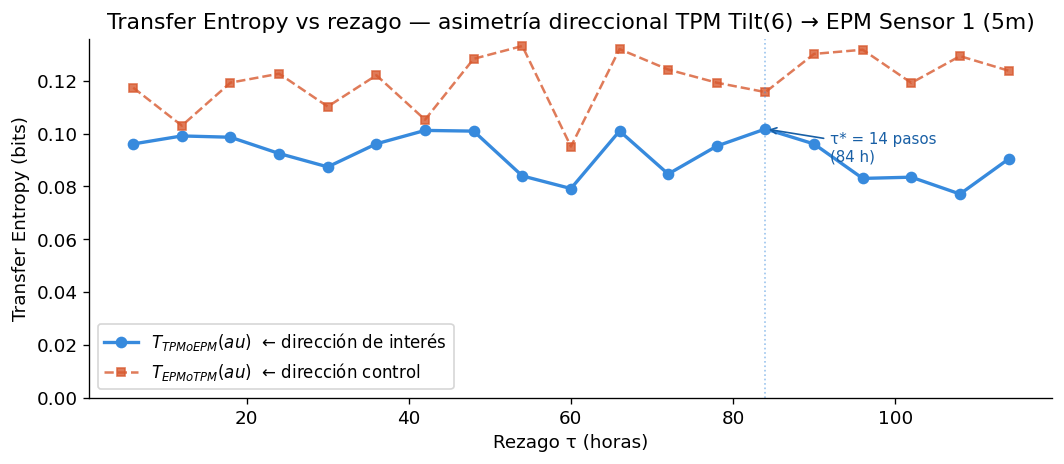

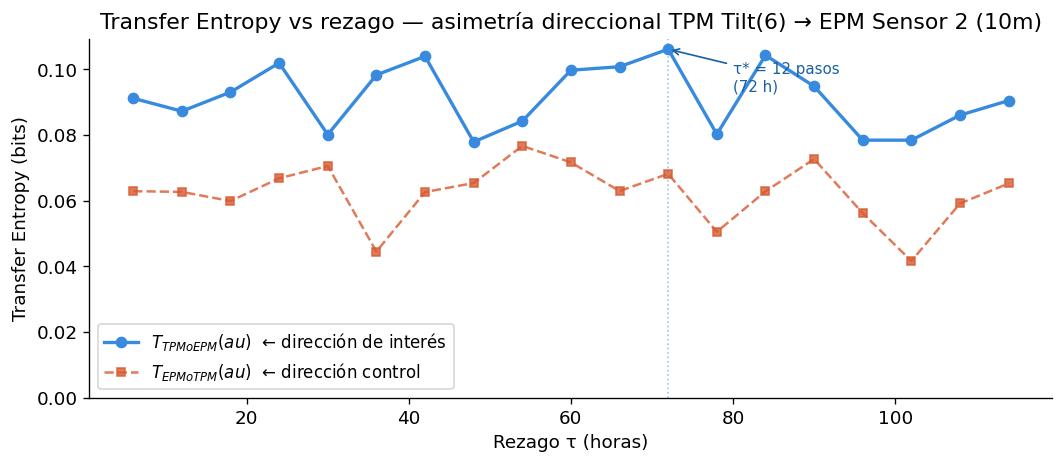

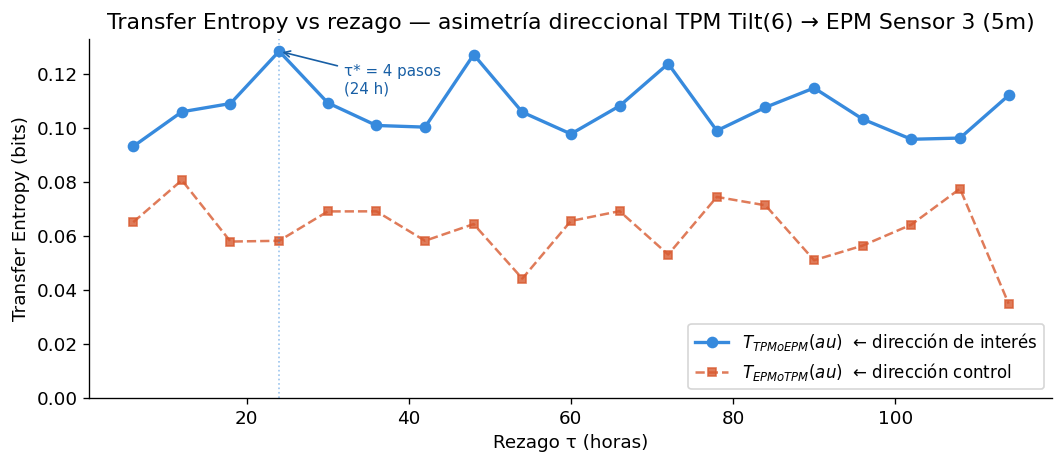

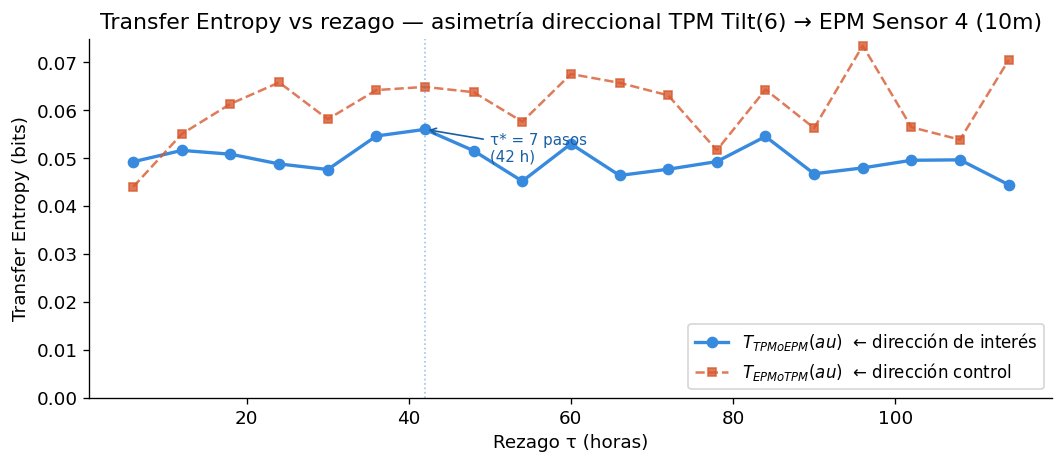

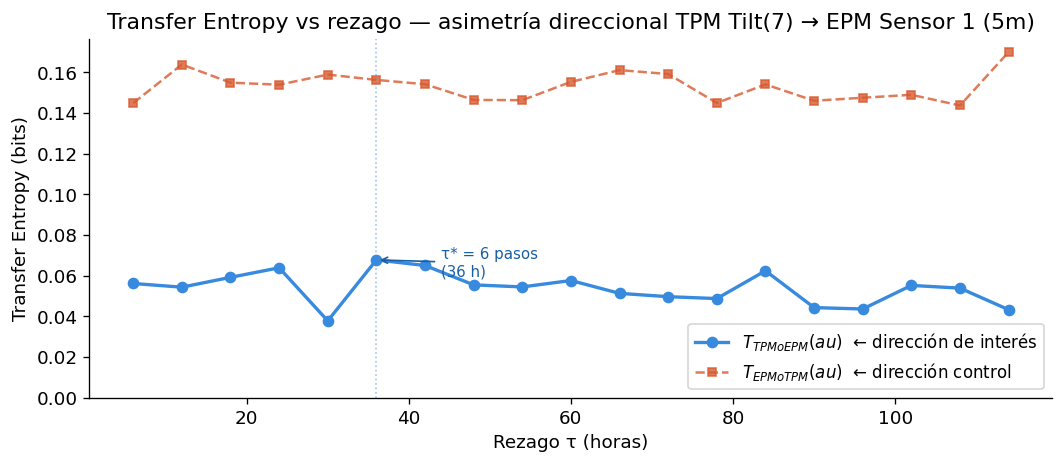

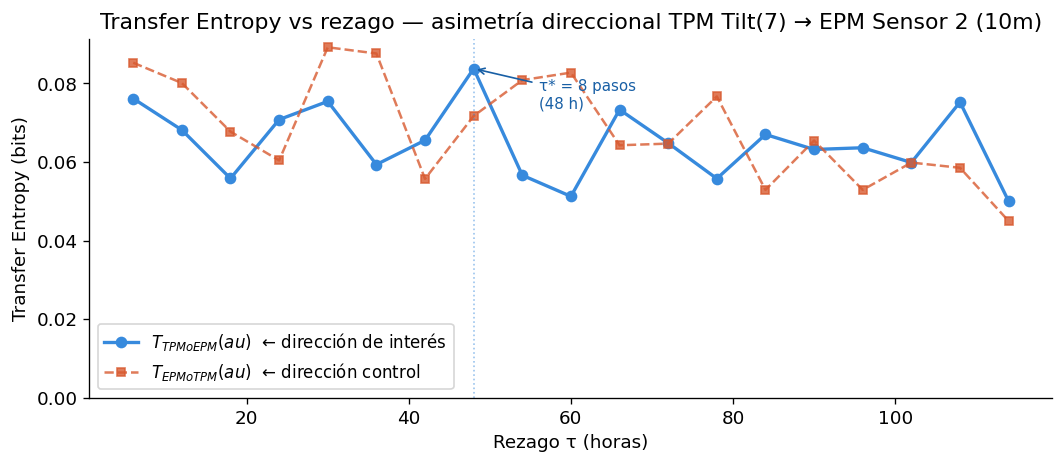

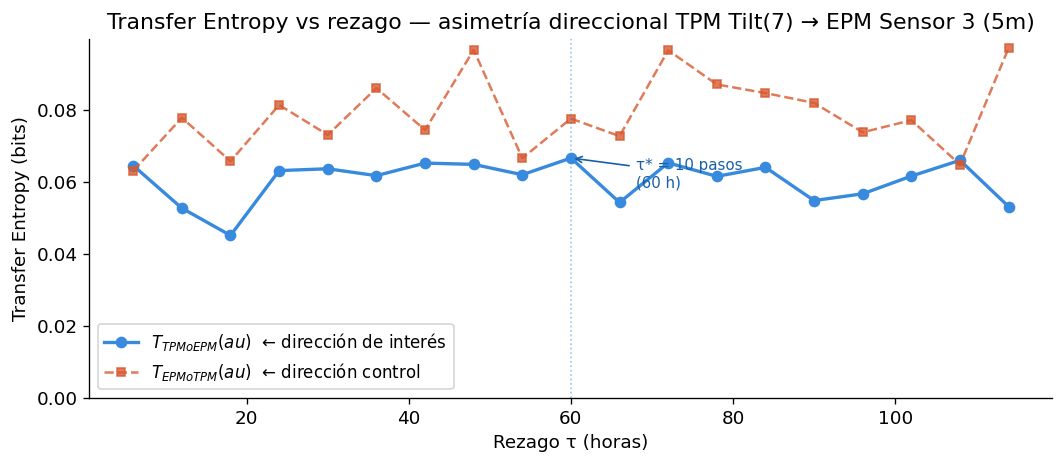

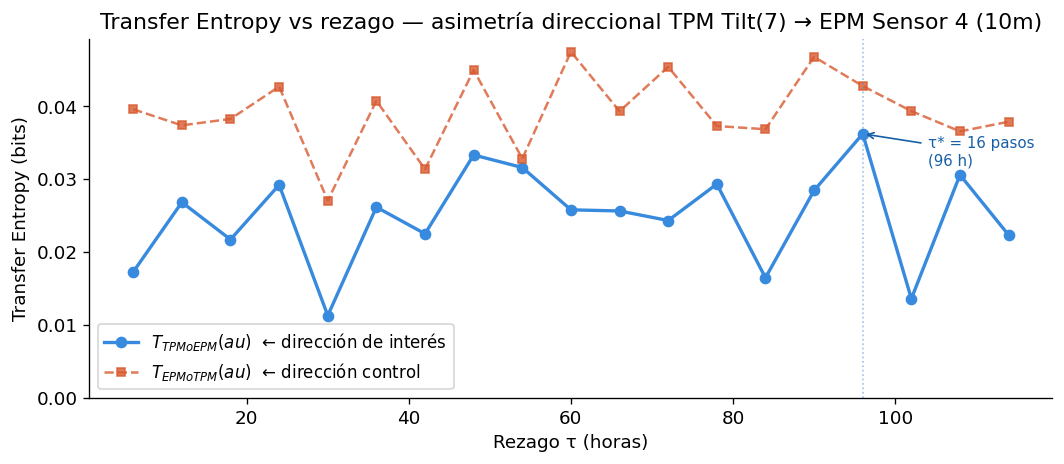

In [8]:
PASO_H = 6  # cada paso de la rejilla son 6 horas, NO 30 minutos

for key, value in te_tpm_epm_dict.items():
  for key2, value2 in value.items():
    tau_optimo = value2["tau_optimo"]
    te_max = value2["te_max"]
    lags = value2["lags"]
    te_tpm_epm = value2["te_tpm_epm"]
    te_epm_tpm = value2["te_epm_tpm"]
    lag_horas = lags * PASO_H
    value2.setdefault("lag_horas", lag_horas)

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.plot(lag_horas, te_tpm_epm, 'o-', color='#378ADD', lw=2,   markersize=6, label=r'$T_{TPM 	o EPM}(	au)$  ← dirección de interés')
    ax.plot(lag_horas, te_epm_tpm, 's--', color='#D85A30', lw=1.5, markersize=5, alpha=0.8, label=r'$T_{EPM 	o TPM}(	au)$  ← dirección control')

    # Marcar el rezago óptimo
    ax.axvline(tau_optimo * PASO_H, color='#378ADD', ls=':', alpha=0.5, lw=1)
    ax.annotate(
        f'τ* = {tau_optimo} pasos\n({tau_optimo * PASO_H} h)',
        xy=(tau_optimo * PASO_H, te_max),
        xytext=(tau_optimo * PASO_H + 8, te_max * 0.88),
        fontsize=9, color='#185FA5',
        arrowprops=dict(arrowstyle='->', color='#185FA5', lw=1)
    )

    ax.set_xlabel(f'Rezago τ (horas)')
    ax.set_ylabel('Transfer Entropy (bits)')
    ax.set_title(f'Transfer Entropy vs rezago — asimetría direccional TPM {key} → EPM {key2}')
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()


---
## Celda 7 · Prueba de significancia estadística (surrogate test)

Saber que $T_{TPM \to EPM} = 0.27$ bits no basta. Hay que demostrar que ese valor **no es producto del azar**.

### ¿Cómo funciona el surrogate test?

La idea es construir la **distribución nula**: ¿cuánto valdría la TE si no hubiera ninguna relación real entre TPM y EPM?

Para eso, **permutamos aleatoriamente** los valores del TPM (barajamos el tiempo al azar). Esto destruye cualquier dependencia temporal entre TPM y EPM, pero mantiene la distribución de valores del TPM.

Hacemos esto 199 veces y calculamos la TE para cada permutación. Esas 199 valores son muestras de "¿qué pasaría si no hubiera información?".

Si la TE observada supera el percentil 95 de esas 199 permutaciones → la dependencia es **estadísticamente real** (p < 0.05).

In [9]:
for tpm_col in tpm_cols:
  print("="*25,f"TPM {tpm_col}","="*25)
  for epm_col in epm_cols:
    print("*"*2,f"EPM {epm_col}","*"*2)
    tmp_val = tpm[tpm_col]
    epm_val = epm[epm_col]
    te_max = te_tpm_epm_dict[tpm_col][epm_col]["te_max"]
    tau_optimo = te_tpm_epm_dict[tpm_col][epm_col]["tau_optimo"]
    rng = np.random.default_rng(42)
    # Generar distribución nula mediante permutaciones
    N_PERMUTACIONES = 199

    distribucion_nula = [
        transfer_entropy(rng.permutation(tmp_val), epm_val, tau=tau_optimo)
        for _ in range(N_PERMUTACIONES)
    ]

    umbral  = np.percentile(distribucion_nula, 95)   # percentil 95 de la H₀
    p_valor = np.mean(np.array(distribucion_nula) >= te_max)

    te_tpm_epm_dict[tpm_col][epm_col].setdefault("p_valor", p_valor)
    te_tpm_epm_dict[tpm_col][epm_col].setdefault("umbral", umbral)
    te_tpm_epm_dict[tpm_col][epm_col]["distribucion_nula"] = distribucion_nula

    print(f"T(TPM→EPM) observada : {te_max:.4f} bits")
    print(f"Umbral al 95% (H₀)   : {umbral:.4f} bits")
    print(f"p-valor estimado     : {p_valor:.4f}")

    # Acá lo que pregunto es qué proporción de los valores de Transfer Entropy
    # de los 199 ejercicios con los datos del TPM desordenados aleatoriamente
    # fueron MAYORES O IGUALES al TE calculado con los datos en su orden temporal
    # original (te_max). Si esa proporción es muy pequeña (menor a alpha),
    # rechazo la hipótesis de que no hay flujo de información TPM→EPM,
    # es decir, concluyo que SÍ existe dicho flujo.
    print(f"¿Significativa?      : {'SÍ  ✓' if p_valor < 0.05 else 'NO  ✗'}  (α = 0.05)")

========================= TPM POT(1) =========================
** EPM Sensor 1 (5m) **
T(TPM→EPM) observada : 0.0639 bits
Umbral al 95% (H₀)   : 0.0216 bits
p-valor estimado     : 0.0000
¿Significativa?      : SÍ  ✓  (α = 0.05)
** EPM Sensor 2 (10m) **
T(TPM→EPM) observada : 0.0719 bits
Umbral al 95% (H₀)   : 0.0322 bits
p-valor estimado     : 0.0000
¿Significativa?      : SÍ  ✓  (α = 0.05)
** EPM Sensor 3 (5m) **
T(TPM→EPM) observada : 0.0900 bits
Umbral al 95% (H₀)   : 0.0248 bits
p-valor estimado     : 0.0000
¿Significativa?      : SÍ  ✓  (α = 0.05)
** EPM Sensor 4 (10m) **
T(TPM→EPM) observada : 0.0322 bits
Umbral al 95% (H₀)   : 0.0102 bits
p-valor estimado     : 0.0000
¿Significativa?      : SÍ  ✓  (α = 0.05)
========================= TPM POT(2) =========================
** EPM Sensor 1 (5m) **
T(TPM→EPM) observada : 0.0640 bits
Umbral al 95% (H₀)   : 0.0253 bits
p-valor estimado     : 0.0000
¿Significativa?      : SÍ  ✓  (α = 0.05)
** EPM Sensor 2 (10m) **
T(TPM→EPM) observada :

##Ejercicio de subrogates desde EPM a TPM

---
## Celda 9 · Reporte final

Este bloque imprime el texto que va directamente al Capítulo 6 de la tesis.

In [13]:
asimetria = te_max / (max(te_epm_tpm) + 1e-12)

print("=" * 60)
print("  REPORTE — Transfer Entropy EPM-TPM")
print("=" * 60)
print()
print(f"  Rezago óptimo τ*         : {tau_optimo} pasos ({tau_optimo * PASO_H} horas)")
print()
print(f"  T(TPM → EPM) en τ*       : {te_max:.4f} bits")
print(f"  T(EPM → TPM) máxima      : {max(te_epm_tpm):.4f} bits")
print(f"  Razón de asimetría       : {asimetria:.2f}×")
print()
print(f"  Surrogate test (N={N_PERMUTACIONES})")
print(f"    Umbral 95%             : {umbral:.4f} bits")
print(f"    p-valor                : {p_valor:.4f}")
print(f"    Resultado              : {'SIGNIFICATIVO ✓' if p_valor < 0.05 else 'NO significativo ✗'}")
print()
print("  Conclusión:")
print(f"    El flujo de información TPM→EPM es estadísticamente")
print(f"    significativo (p={p_valor:.4f}) con una asimetría de {asimetria:.2f}×")
print(f"    respecto a la dirección inversa. Esto constituye")
print(f"    evidencia de dependencia estadistica dirigida TPM->EPM,")
print(f"    no de causalidad fisica.")
print("=" * 60)

  REPORTE — Transfer Entropy EPM-TPM

  Rezago óptimo τ*         : 16 pasos (96 horas)

  T(TPM → EPM) en τ*       : 0.0362 bits
  T(EPM → TPM) máxima      : 0.0475 bits
  Razón de asimetría       : 0.76×

  Surrogate test (N=199)
    Umbral 95%             : 0.0170 bits
    p-valor                : 0.0000
    Resultado              : SIGNIFICATIVO ✓

  Conclusión:
    El flujo de información TPM→EPM es estadísticamente
    significativo (p=0.0000) con una asimetría de 0.76×
    respecto a la dirección inversa. Esto constituye
    evidencia de dependencia estadistica dirigida TPM->EPM,
    no de causalidad fisica.


In [14]:
# BLOQUE 2 REEMPLAZO — Heatmaps individuales en PDF para LaTeX
# Requiere que ya existan: tpm_cols, epm_cols, te_tpm_epm_dict

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from pathlib import Path

# Carpeta de salida
out_dir = Path("figuras_te_pdf")
out_dir.mkdir(exist_ok=True)

# Construir matrices 4 x 14
n_epm = len(epm_cols)
n_tpm = len(tpm_cols)

mat_forward  = np.zeros((n_epm, n_tpm))   # T_{TPM -> EPM}(tau*)
mat_backward = np.zeros((n_epm, n_tpm))   # T_{EPM -> TPM}(maximo sobre rezagos)
mat_asim     = np.zeros((n_epm, n_tpm))   # Razon de asimetria
mat_pval     = np.zeros((n_epm, n_tpm))   # p-valor surrogate test

for i, epm_col in enumerate(epm_cols):
    for j, tpm_col in enumerate(tpm_cols):
        d = te_tpm_epm_dict[tpm_col][epm_col]
        mat_forward[i, j]  = d["te_max"]
        mat_backward[i, j] = max(d["te_epm_tpm"])
        mat_asim[i, j]     = d["te_max"] / (max(d["te_epm_tpm"]) + 1e-12)
        mat_pval[i, j]     = d["p_valor"]

sig_mask = mat_pval < 0.05

# Etiquetas
tpm_labels = list(tpm_cols)

epm_labels = [
    c.replace("Sensor 1 (5m)", "S1\n(5m)")
     .replace("Sensor 2 (10m)", "S2\n(10m)")
     .replace("Sensor 3 (5m)", "S3\n(5m)")
     .replace("Sensor 4 (10m)", "S4\n(10m)")
    for c in epm_cols
]


def draw_heatmap_individual(
    matrix,
    cmap,
    title,
    filename,
    fmt=".3f",
    sig_mask=None,
    norm=None,
    vmin=None,
    vmax=None,
    cbar_label="bits",
    add_note=None,
):
    """
    Exporta un heatmap individual en PDF.
    El PDF es adecuado para LaTeX. dpi controla la resolucion del raster de imshow.
    """
    fig, ax = plt.subplots(figsize=(14, 4.8), constrained_layout=True)

    kw = dict(aspect="auto", interpolation="nearest")
    if norm is not None:
        kw["norm"] = norm
    else:
        if vmin is not None:
            kw["vmin"] = vmin
        if vmax is not None:
            kw["vmax"] = vmax

    im = ax.imshow(matrix, cmap=cmap, **kw)
    cbar = fig.colorbar(im, ax=ax, fraction=0.030, pad=0.018)
    cbar.set_label(cbar_label, fontsize=9)
    cbar.ax.tick_params(labelsize=8)

    # Limites para color de texto
    if norm is not None:
        def is_dark(value):
            return norm(value) > 0.63 or norm(value) < 0.18
    else:
        vlo = np.nanmin(matrix) if vmin is None else vmin
        vhi = np.nanmax(matrix) if vmax is None else vmax
        threshold = vlo + 0.60 * (vhi - vlo)

        def is_dark(value):
            return value > threshold

    # Anotaciones
    for ii in range(matrix.shape[0]):
        for jj in range(matrix.shape[1]):
            texto = f"{matrix[ii, jj]:{fmt}}"
            if sig_mask is not None and sig_mask[ii, jj]:
                texto += "\n*"

            color_txt = "white" if is_dark(matrix[ii, jj]) else "black"

            ax.text(
                jj,
                ii,
                texto,
                ha="center",
                va="center",
                fontsize=7.5,
                color=color_txt,
                linespacing=1.15,
            )

    ax.set_xticks(range(n_tpm))
    ax.set_xticklabels(tpm_labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(n_epm))
    ax.set_yticklabels(epm_labels, fontsize=9)

    ax.set_xlabel("Serie TPM", fontsize=9)
    ax.set_ylabel("Sensor EPM", fontsize=9)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)

    # Cuadricula fina para separar celdas
    ax.set_xticks(np.arange(-0.5, n_tpm, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_epm, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    if add_note:
        fig.text(0.01, -0.02, add_note, ha="left", va="top", fontsize=8)

    output_path = out_dir / filename
    fig.savefig(output_path, format="png", dpi=600, bbox_inches="tight")
    plt.close(fig)
    print(f"Guardado: {output_path}")


print("Exportando heatmaps individuales en PDF...")

# Heatmap 1: flujo TPM -> EPM
draw_heatmap_individual(
    matrix=mat_forward,
    cmap="Blues",
    title=r"$T_{TPM \to EPM}(\tau^*)$ - Flujo de informacion TPM hacia EPM",
    filename="heatmap_01_te_tpm_a_epm.png",
    fmt=".3f",
    sig_mask=sig_mask,
    vmin=0,
    cbar_label="Transfer Entropy [bits]",
    add_note="* indica p < 0.05 segun surrogate test."
)

# Heatmap 2: flujo EPM -> TPM
draw_heatmap_individual(
    matrix=mat_backward,
    cmap="Oranges",
    title=r"$T_{EPM \to TPM}(\tau)_{max}$ - Flujo de informacion EPM hacia TPM",
    filename="heatmap_02_te_epm_a_tpm.png",
    fmt=".3f",
    vmin=0,
    cbar_label="Transfer Entropy [bits]"
)

# Heatmap 3: razon de asimetria
vmax_asim = max(float(np.nanmax(mat_asim)) * 1.05, 2.0)
norm_asim = TwoSlopeNorm(vmin=0.0, vcenter=1.0, vmax=vmax_asim)

draw_heatmap_individual(
    matrix=mat_asim,
    cmap="RdBu_r",
    title=r"$T_{TPM \to EPM}(\tau^*) / T_{EPM \to TPM}$ - Razon de asimetria",
    filename="heatmap_03_razon_asimetria.png",
    fmt=".2f",
    sig_mask=sig_mask,
    norm=norm_asim,
    cbar_label="Razon de asimetria",
    add_note="Valores > 1 indican predominio TPM -> EPM; valores < 1 indican predominio EPM -> TPM. * indica p < 0.05."
)

# Heatmap 4: p-valores
draw_heatmap_individual(
    matrix=mat_pval,
    cmap="RdYlGn_r",
    title="p-valor surrogate test - Evidencia estadistica del flujo TPM hacia EPM",
    filename="heatmap_04_pvalor_surrogate.png",
    fmt=".3f",
    vmin=0,
    vmax=0.10,
    cbar_label="p-valor",
    add_note="Verde indica p pequeno; se considera significativo p < 0.05."
)

print("Listo. PDFs creados en la carpeta:", out_dir.resolve())

Exportando heatmaps individuales en PDF...
Guardado: figuras_te_pdf\heatmap_01_te_tpm_a_epm.png
Guardado: figuras_te_pdf\heatmap_02_te_epm_a_tpm.png
Guardado: figuras_te_pdf\heatmap_03_razon_asimetria.png
Guardado: figuras_te_pdf\heatmap_04_pvalor_surrogate.png
Listo. PDFs creados en la carpeta: C:\Users\aeagu\Documents\Admision maestria - Matematicas\Tesis\Códigos\figuras_te_pdf


#CCM

In [15]:
df_tpmepm = pd.concat([tpm,epm],axis=1)
df_tpmepm

,freq,POT(1),POT(2),POT(3),POT(4),POT(5),POT(6),POT(7),Tilt(1),Tilt(2),Tilt(3),Tilt(4),Tilt(5),Tilt(6),Tilt(7),Sensor 1 (5m),Sensor 2 (10m),Sensor 3 (5m),Sensor 4 (10m)
0,360.0,8.082740,9.714733,8.143721,8.569899,11.073675,9.301433,9.351190,-0.003088,-0.104500,-0.081261,-0.010618,-0.074488,-0.083057,-0.044929,3158.6887,2792.5084,3170.7856,3004.6062
1,360.0,8.082781,9.714744,8.147375,8.573360,11.073650,9.305238,9.354521,-0.003073,-0.104492,-0.081319,-0.010637,-0.074473,-0.083064,-0.044931,3158.6887,2792.9094,3171.8898,3004.6062
2,360.0,8.082798,9.714785,8.152645,8.576698,11.075625,9.309115,9.358301,-0.003070,-0.104500,-0.081277,-0.010631,-0.074471,-0.083068,-0.044925,3158.6887,2792.5084,3173.7066,3004.6062
3,360.0,8.082740,9.714612,8.144846,8.574779,11.075005,9.290893,9.349352,-0.003090,-0.104485,-0.081230,-0.010562,-0.074506,-0.083075,-0.044926,3159.5062,2792.5084,3172.3172,3004.6062
4,360.0,8.082769,9.714588,8.144113,8.574645,11.075065,9.298288,9.350774,-0.003078,-0.104485,-0.081323,-0.010609,-0.074482,-0.083068,-0.044922,3159.1152,2792.2076,3171.8898,3004.6062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,360.0,8.128937,9.703026,7.874609,8.552941,11.107520,9.273832,9.429535,-0.003295,-0.104453,-0.081439,-0.010716,-0.074449,-0.083160,-0.044916,3162.3153,2787.1969,3175.0963,3005.2996
885,360.0,8.129009,9.705659,7.881890,8.554438,11.107780,9.285828,9.435174,-0.003289,-0.104464,-0.081451,-0.010757,-0.074438,-0.083150,-0.044912,3161.8885,2790.5034,3173.7066,3005.2996
886,360.0,8.129052,9.704605,7.888861,8.558635,11.108000,9.290255,9.440618,-0.003281,-0.104474,-0.081417,-0.010753,-0.074428,-0.083156,-0.044913,3161.8885,2790.2028,3173.7066,3005.2996
887,360.0,8.128944,9.704857,7.875603,8.553975,11.107700,9.272581,9.430837,-0.003314,-0.104446,-0.081360,-0.010668,-0.074460,-0.083166,-0.044920,3162.7066,2786.7962,3175.0963,3004.9876


In [16]:


columnas_tpm_epm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
                     'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)',
                     'Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

lib_range  = "1 600"
pred_range = "601 881"
maxE = 40    # mismo maxE para todas, para que la tabla sea comparable

tabla_E = []

for col in columnas_tpm_epm:
    resultado = pyEDM.EmbedDimension(
        dataFrame = df_tpmepm,
        lib     = lib_range,
        pred    = pred_range,
        maxE    = maxE,
        columns = [col],
        target  = [col],
        showPlot = False   # apaga el gráfico automático, ya vamos a tabular
    )
    E_optimo = resultado.loc[resultado['rho'].idxmax(), 'E']
    rho_max  = resultado['rho'].max()
    tabla_E.append({'serie': col, 'E_optimo': E_optimo, 'rho_max': rho_max})

tabla_E = pd.DataFrame(tabla_E)
print(tabla_E)

             serie  E_optimo   rho_max
0           POT(1)         4  0.738156
1           POT(2)         2  0.985110
2           POT(3)         5  0.610725
3           POT(4)         8  0.902546
4           POT(5)         2  0.979826
5           POT(6)         9  0.796835
6           POT(7)         4  0.833107
7          Tilt(1)        37  0.434320
8          Tilt(2)         4  0.437576
9          Tilt(3)        24  0.372383
10         Tilt(4)         8  0.434131
11         Tilt(5)         4  0.555420
12         Tilt(6)         6  0.672611
13         Tilt(7)        12  0.424944
14   Sensor 1 (5m)        26  0.369449
15  Sensor 2 (10m)        18  0.350547
16   Sensor 3 (5m)        36  0.379983
17  Sensor 4 (10m)        14  0.707032


In [17]:
from itertools import product

E_optimo = tabla_E.set_index('serie')['E_optimo'].to_dict()

series_tpm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
              'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)']
series_epm = ['Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

sample = 100
exclusionRadius = 10       # provisional

resultados_ccm = {}

for i, (tpm, epm) in enumerate(product(series_tpm, series_epm)):
    print(f"[{i+1}/56] {tpm} vs {epm}...", flush=True)
    E_par = max(E_optimo[tpm], E_optimo[epm])

    # el arranque de la librería debe ser mayor que E_par;
    # dejamos un margen de +10 para que el primer punto no sea al filo del mínimo
    inicio = E_par + 10
    libSizes_par = f"{inicio} 800 40"

    res = pyEDM.CCM(
        dataFrame = df_tpmepm,
        E = E_par,
        columns = [tpm],
        target  = [epm],
        libSizes = libSizes_par,
        sample = sample,
        exclusionRadius = exclusionRadius,
        showPlot = False
    )
    resultados_ccm[(tpm, epm)] = res

resumen = []
for (tpm, epm), res in resultados_ccm.items():
    res_sorted = res.sort_values('LibSize')
    fila_final = res_sorted.iloc[-1]
    col_tpm_a_epm = res.columns[1]
    col_epm_a_tpm = res.columns[2]

    resumen.append({
        'TPM': tpm,
        'EPM': epm,
        'E_par': max(E_optimo[tpm], E_optimo[epm]),
        'libSize_inicio': max(E_optimo[tpm], E_optimo[epm]) + 10,
        'skill_TPMmanifold_predice_EPM': fila_final[col_tpm_a_epm],
        'skill_EPMmanifold_predice_TPM': fila_final[col_epm_a_tpm],
    })

resumen_df = pd.DataFrame(resumen)
print(resumen_df.sort_values('skill_TPMmanifold_predice_EPM', ascending=False))

[1/56] POT(1) vs Sensor 1 (5m)...
[2/56] POT(1) vs Sensor 2 (10m)...
[3/56] POT(1) vs Sensor 3 (5m)...
[4/56] POT(1) vs Sensor 4 (10m)...
[5/56] POT(2) vs Sensor 1 (5m)...
[6/56] POT(2) vs Sensor 2 (10m)...
[7/56] POT(2) vs Sensor 3 (5m)...
[8/56] POT(2) vs Sensor 4 (10m)...
[9/56] POT(3) vs Sensor 1 (5m)...
[10/56] POT(3) vs Sensor 2 (10m)...
[11/56] POT(3) vs Sensor 3 (5m)...
[12/56] POT(3) vs Sensor 4 (10m)...
[13/56] POT(4) vs Sensor 1 (5m)...
[14/56] POT(4) vs Sensor 2 (10m)...
[15/56] POT(4) vs Sensor 3 (5m)...
[16/56] POT(4) vs Sensor 4 (10m)...
[17/56] POT(5) vs Sensor 1 (5m)...
[18/56] POT(5) vs Sensor 2 (10m)...
[19/56] POT(5) vs Sensor 3 (5m)...
[20/56] POT(5) vs Sensor 4 (10m)...
[21/56] POT(6) vs Sensor 1 (5m)...
[22/56] POT(6) vs Sensor 2 (10m)...
[23/56] POT(6) vs Sensor 3 (5m)...
[24/56] POT(6) vs Sensor 4 (10m)...
[25/56] POT(7) vs Sensor 1 (5m)...
[26/56] POT(7) vs Sensor 2 (10m)...
[27/56] POT(7) vs Sensor 3 (5m)...
[28/56] POT(7) vs Sensor 4 (10m)...
[29/56] Tilt(1)

---

## Referencia

Schreiber, T. (2000). *Measuring Information Transfer*. **Physical Review Letters**, 85(2), 461–464. https://doi.org/10.1103/PhysRevLett.85.461

---
*Tesis de Maestría en Ciencias Matemáticas Aplicadas — Universidad Nacional de Colombia*  
*Autor: Alejandro Enrique Aguilar Sánchez*